> **Superseded (constitución 7.0.0, 2026-11-09).** Este notebook trata los quiebres a nivel artículo (579 artículos) y planeaba seleccionar el modelo por artículo. Lo reemplaza la cadena 03b → 03c → 03d → nuevo nb 04 (`04_feature_engineering_y_seleccion_de_modelo.ipynb`): tratamiento por tienda y un único CatBoost global. Se conserva sin uso como registro de lo probado; registro de etapas en `specs/001-abc-xyz-share-forecast/nb04-superseded-etapas.md`.

# 04 · Feature engineering y selección de modelo

**Propósito:** construir las series por bloques de 28 días de los artículos seleccionados en el nb 03 (`targets`), con su tratamiento de ceros congelado; preparar las variables; elegir por artículo el modelo de pronóstico (seasonal naive, SARIMAX, XGBoost, LightGBM o CatBoost) solo con train, y reentrenar los ganadores con los años 1–4. La evaluación en test es del nb 05.

**Etapas** (el estado de cada una vive en `specs/001-abc-xyz-share-forecast/nb04-etapas.md`):

| # | Etapa |
|---|---|
| 1 | Carga de datos crudos |
| 2 | Artefactos congelados del nb 03 |
| 3 | Tratamiento de ceros y filtro (diario) |
| 4 | Bloques de 28 días, bloques no válidos y partición por artículo |
| 5 | Variables de calendario |
| 6 | Feature engineering (6a objetivo · 6b eventos · 6c reglas comunes; 6d sin efecto) |
| 7 | Split temporal |
| 8 | Análisis bivariado (pendiente) |
| 9 | Datasets por modelo |
| 10 | Folds |
| 11 | Seasonal naive |
| 12 | SARIMAX |
| 13 | Boosting (13a XGBoost · 13b LightGBM · 13c CatBoost) |
| 14 | Filtro frente al seasonal naive y selección por artículo |
| 15 | Reentrenamiento de los ganadores con Y1–Y4 |
| 16 | Persistencia y cierre |

## Configuración

**Qué hace:** fija la raíz del proyecto (rutas relativas), activa `%autoreload` para tomar los cambios de `src/` sin reiniciar el kernel, carga la configuración validada e imprime las versiones de Python y de las librerías (R6).
**Decisión:** la semilla se fija en la primera etapa que use azar (la 6c, para la muestra del chequeo manual), y se declara en `params.toml` con su historial, porque la constitución pide que viva en la configuración.

In [87]:
%load_ext autoreload
%autoreload 2

import os
import platform
import sys
from importlib.metadata import version
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import all_years, load_validated_config, train_end

pd.set_option("display.max_columns", 30)
%matplotlib inline

cfg = load_validated_config()
years = all_years(cfg)
START_D, END_D = years["Y1"][0], years["Y5"][1]
TRAIN_END = train_end(cfg)
TEST_START = TRAIN_END + 1

LIBS = ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "matplotlib", "pyarrow"]
display(pd.Series({"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}}, name="versión").to_frame())
display(pd.Series({"START_D": START_D, "TRAIN_END": TRAIN_END, "TEST_START": TEST_START, "END_D": END_D}, name="día").to_frame())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,versión
python,3.12.3
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
statsmodels,0.15.0
matplotlib,3.11.2
pyarrow,26.0.0


,día
START_D,122
TRAIN_END,1577
TEST_START,1578
END_D,1941


## Etapa 1 · Carga de datos crudos

**Objetivo:** leer los tres archivos originales de M5 sin modificarlos (Principio V) y revisar su forma antes de cualquier tratamiento.
**Entradas:** `data/raw/sales_train_evaluation.csv`, `data/raw/calendar.csv`, `data/raw/sell_prices.csv`.
**Salidas:** `units_raw` (arreglo series × día) y `series_index`, `calendar`, `prices`.
**Decisión:** se usan los lectores existentes de `src/data.py` (los mismos de la validación de datos), sin reescribirlos. Esta etapa solo describe: el enmascarado de prelanzamiento y rechazos ya está hecho en los datos intermedios (`load_interim`), que usa la Etapa 3, igual que el nb 03.

### 1.1 · Ventas

**Revisar:** 30,490 series (10 tiendas × 3,049 artículos) y 1,941 días; sin nulos, negativos ni no enteros.

In [88]:
from src.data import load_sales, sales_overview

In [89]:
units_raw, series_index = load_sales(cfg)

In [90]:
overview = sales_overview(units_raw, series_index)
display(overview.to_frame("ventas crudas").style.format("{:,.2f}"))
assert overview["series"] == 30_490 and overview["stores"] == 10 and overview["items"] == 3_049
assert overview["days"] == cfg["data"]["last_day"] == END_D
assert overview["nan_cells"] == overview["negative_cells"] == overview["non_integer_cells"] == 0
display(series_index.head())
display(pd.DataFrame(units_raw[:5, :8], index=series_index["item_id"].head(), columns=[f"d_{d}" for d in range(1, 9)]))

,ventas crudas
series,"30,490.00"
stores,10.00
items,"3,049.00"
days,"1,941.00"
cells,"59,181,090.00"
nan_cells,0.00
negative_cells,0.00
non_integer_cells,0.00
zero_cells,"40,241,819.00"
zero_pct,68.00


,store_id,item_id,csv_row
0,CA_1,FOODS_1_001,1612
1,CA_1,FOODS_1_002,1613
2,CA_1,FOODS_1_003,1614
3,CA_1,FOODS_1_004,1615
4,CA_1,FOODS_1_005,1616


,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8
item_id,,,,,,,,
FOODS_1_001,3.0,0.0,0.0,1.0,4.0,2.0,0.0,2.0
FOODS_1_002,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
FOODS_1_003,0.0,0.0,0.0,0.0,1.0,3.0,1.0,1.0
FOODS_1_004,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
FOODS_1_005,3.0,9.0,3.0,3.0,0.0,2.0,1.0,2.0


### 1.2 · Calendario

**Qué hace:** `validate_calendar` detiene el proceso si las fechas no son válidas y continuas, si falta algún día hasta `d_1941` o si una semana `wm_yr_wk` tiene más de 7 días (FR-003). Se muestran los tipos y nulos por columna, y las fechas de los límites del split.
**Revisar:** 1,969 días (2011-01-29 a 2016-06-19; los 28 posteriores a `d_1941` no tienen ventas). Los nulos de `event_*` son días sin evento, no faltantes; se tratan en la Etapa 5.

In [91]:
from src.data import load_calendar, profile_frame, validate_calendar

In [92]:
calendar = load_calendar(cfg)

In [93]:
validate_calendar(calendar, END_D)
calendar["d_num"] = calendar["d"].str.removeprefix("d_").astype(int)
print(f"calendario: {calendar.shape} · {calendar['date'].min()} a {calendar['date'].max()}")
display(profile_frame(calendar.drop(columns="d_num")))
limits = {"inicio Y1": START_D, "fin train (Y4)": TRAIN_END, "inicio test (Y5)": TEST_START, "fin test": END_D}
display(pd.DataFrame([(k, d, *calendar.loc[calendar["d_num"] == d, ["date", "weekday"]].iloc[0]) for k, d in limits.items()],
                     columns=["límite", "día", "fecha", "día de la semana"]).set_index("límite"))
assert (TRAIN_END - START_D + 1) == 52 * 28 and (END_D - TEST_START + 1) == 13 * 28

calendario: (1969, 15) · 2011-01-29 a 2016-06-19


,dtype,nulls,null_pct,unique
date,str,0,0.00,1969
wm_yr_wk,int64,0,0.00,282
weekday,str,0,0.00,7
wday,int64,0,0.00,7
month,int64,0,0.00,12
year,int64,0,0.00,6
d,str,0,0.00,1969
event_name_1,str,1807,91.77,30
event_type_1,str,1807,91.77,4
event_name_2,str,1964,99.75,4


,día,fecha,día de la semana
límite,,,
inicio Y1,122,2011-05-30,Monday
fin train (Y4),1577,2015-05-24,Sunday
inicio test (Y5),1578,2015-05-25,Monday
fin test,1941,2016-05-22,Sunday


### 1.3 · Precios

**Qué hace:** lee los precios semanales por tienda, artículo y `wm_yr_wk`.
**Revisar:** sin nulos, precios positivos, una fila por tienda-artículo-semana y semanas dentro del rango del calendario. Los precios ausentes son filas que faltan (no nulos explícitos); los trató la validación de datos.

In [94]:
from src.data import load_prices

In [95]:
prices = load_prices(cfg)

In [96]:
print(f"precios: {prices.shape}")
display(profile_frame(prices))
display(prices["sell_price"].describe().to_frame("sell_price").T)
assert (prices["sell_price"] > 0).all()
assert not prices.duplicated(["store_id", "item_id", "wm_yr_wk"]).any()
assert prices["wm_yr_wk"].between(calendar["wm_yr_wk"].min(), calendar["wm_yr_wk"].max()).all()
assert set(prices["item_id"]) == set(series_index["item_id"]) and set(prices["store_id"]) == set(series_index["store_id"])
display(prices.head())

precios: (6841121, 5)


,dtype,nulls,null_pct,unique
store_id,str,0,0.0,10
item_id,str,0,0.0,3049
wm_yr_wk,int64,0,0.0,282
sell_price,float64,0,0.0,1048
csv_row,int64,0,0.0,6841121


,count,mean,std,min,25%,50%,75%,max
sell_price,6841121.0,4.410952,3.408814,0.01,2.18,3.47,5.84,107.32


,store_id,item_id,wm_yr_wk,sell_price,csv_row
0,CA_1,HOBBIES_1_001,11325,9.58,0
1,CA_1,HOBBIES_1_001,11326,9.58,1
2,CA_1,HOBBIES_1_001,11327,8.26,2
3,CA_1,HOBBIES_1_001,11328,8.26,3
4,CA_1,HOBBIES_1_001,11329,8.26,4


## Etapa 2 · Artefactos congelados del nb 03

**Objetivo:** cargar lo que el nb 03 congeló para los artículos a modelar, sin recalcular nada (R5).
**Entradas:** `data/processed/targets.parquet` (vía `load_frozen`, que verifica su SHA-256 contra el manifiesto) y la lista de artículos de `series_index` (Etapa 1).
**Salidas:** `targets` (592 filas) e `items` (3,049 filas: todos los artículos con `is_target` y, en los modelados, sus clases y reglas congeladas).
**Decisión:** las clases ABC y XYZ se toman por artículo de `targets` (merge por `item_id`), que es lo que heredó el nb 03; los cortes no se persisten ni se usan aquí. `long_run` (largo mínimo de racha de ceros que se trata como no observada) y `min_days` (días observados mínimos por bloque de 28) vienen por artículo en el mismo archivo.
**Excluidos:** los 2,457 artículos restantes no se modelan. Su motivo (sin XYZ limpio, regla de bloques en test o segmento distinto de AX/AY/AZ) quedó en el nb 03 (Etapas 12–14) y no se persistió.
**Revisar:** 592 artículos (AX 207, AY 251, AZ 134, 59,88 % del gasto de train), todos de clase A, XYZ igual a la letra de la celda, tratamiento igual al de `treatment_map` y `min_days` ∈ {4, 5, 9} (m por tercil de p₀).

In [97]:
from src.features import flag_targets
from src.freeze import load_frozen

In [98]:
targets = load_frozen("targets")

In [99]:
items = flag_targets(series_index["item_id"], targets)

In [100]:
EXPECTED_CELLS = {"AX": 207, "AY": 251, "AZ": 134}   # reportados en la Etapa 14 del nb 03

summary = targets.groupby("cell").agg(n_items=("item_id", "size"), spend_share=("spend_share", "sum"),
                                      long_run_median=("long_run", "median"), cv_train_median=("cv_train", "median"))
summary.loc["Total"] = [len(targets), targets["spend_share"].sum(), targets["long_run"].median(), targets["cv_train"].median()]
display(summary.style.format({"n_items": "{:,.0f}", "spend_share": "{:.2%}", "long_run_median": "{:.0f}", "cv_train_median": "{:.1f}"}))
display(pd.crosstab(targets["cell"], targets["min_days"], margins=True).rename_axis(columns="min_days"))
display(items["is_target"].value_counts().rename({True: "se modela", False: "excluido"}).to_frame("artículos"))

assert targets["cell"].value_counts().to_dict() == EXPECTED_CELLS
assert round(targets["spend_share"].sum() * 100, 2) == 59.88
assert (targets["abc_class"] == "A").all() and (targets["xyz_class"] == targets["cell"].str[1]).all()
assert (targets["treatment"] == targets["cell"].map(cfg["treatment_map"])).all()
assert set(targets["min_days"]) <= {4, 5, 9} and (targets["long_run"] >= 2).all()
assert targets[["long_run", "min_days", "cv_train"]].notna().all().all()
assert len(items) == 3_049 and items["is_target"].sum() == 592
display(items[items["is_target"]].head())

,n_items,spend_share,long_run_median,cv_train_median
cell,,,,
AX,207,20.38%,3,17.4
AY,251,25.59%,4,31.5
AZ,134,13.91%,6,53.0
Total,592,59.88%,4,29.0


min_days,4,5,9,All
cell,,,,
AX,166,40,1,207
AY,138,90,23,251
AZ,24,62,48,134
All,328,192,72,592


,artículos
is_target,
excluido,2457
se modela,592


,item_id,is_target,cell,abc_class,xyz_class,cv_train,long_run,min_days,treatment
3,FOODS_1_004,True,AY,A,Y,31.013285,5,5,periodic_review_replenishment
10,FOODS_1_012,True,AY,A,Y,34.019096,3,4,periodic_review_replenishment
16,FOODS_1_018,True,AX,A,X,19.764429,3,4,regular_replenishment
21,FOODS_1_023,True,AZ,A,Z,46.366132,4,4,promotion_priority
22,FOODS_1_024,True,AY,A,Y,25.271764,4,4,periodic_review_replenishment


## Etapa 3 · Tratamiento de ceros congelado y filtro de artículos (nivel diario)

**Objetivo:** dejar la serie diaria de los 592 artículos con el tratamiento de ceros del nb 03, aplicado con los `long_run` congelados y sin recalcular parámetros (R5).
**Entradas:** `load_interim` (unidades por artículo y día, con prelanzamiento y rechazos ya en NaN; total de la cadena por día) y `targets` (Etapa 2).
**Salidas:** `units_lc` (ciclo de vida), `runs_kind` (rachas clasificadas) y `units_treated` (quiebres en NaN), artículo × día de d_122 a d_1941.
**Decisión (constitución 4.0.0, Principio II):**
- El **ciclo de vida va de la primera a la última venta**: los ceros anteriores y posteriores quedan en NaN, igual que en el nb 03.
- Una racha **interna** de ceros con largo ≥ `long_run` del artículo es un quiebre y sus ceros pasan a NaN; las más cortas son demanda observada.
- **En el modelado, el valor de un bloque de 28 días es la suma de sus unidades** (Etapa 4). Enmascarar ceros no cambia esa suma, y `min_days` no se aplica: solo servía para el CV de la clasificación.

Las funciones de ciclo de vida y enmascarado se llevaron del nb 03 a `src/segmentation.py` sin cambiar su lógica.

In [101]:
from src.data import load_interim, to_daily_frame
from src.segmentation import classify_runs, find_zero_runs, lifecycle_bounds, mask_breaks, trim_lifecycle

### 3.1 · Datos intermedios y verificación contra el nb 03

**Qué hace:** carga los intermedios hasta d_1941 y arma la serie diaria de los 3,049 artículos. Con el modo del nb 03 (recorte en ambos extremos) se verifica que las funciones llevadas a `src/` reproducen sus conteos.
**Revisar:** 16,634 ceros recortados (`leading` + `trailing` de la inspección del nb 03) y 235,607 rachas, todas internas, con largo medio 2,832 y máximo 1,249 (nb 03, 1.1 y 1.4). Los conteos de quiebres del nb 03 (11,762 rachas) usan el `long_run` de los 3,049 artículos, que solo quedó congelado para los 592; por eso la verificación de quiebres se hace en la 3.4, comparando con el modo del nb 03 sobre los mismos 592.

In [102]:
agg = load_interim(cfg, END_D)

In [103]:
units_all = to_daily_frame(agg["item_units"], agg["item_ids"], START_D, END_D)

In [104]:
bounds_nb03 = lifecycle_bounds(units_all)
units_lc_nb03 = trim_lifecycle(units_all, bounds_nb03)
runs_nb03 = find_zero_runs(units_lc_nb03)
check_nb03 = pd.Series({
    "ceros recortados": int(((units_all == 0) & units_lc_nb03.isna()).sum().sum()),
    "rachas": len(runs_nb03),
    "largo medio": round(runs_nb03["length"].mean(), 6),
    "largo máximo": runs_nb03["length"].max(),
})
display(check_nb03.to_frame("modo nb 03"))
print("units_all:", units_all.shape)
assert check_nb03["ceros recortados"] == 16_634 and check_nb03["rachas"] == 235_607
assert (runs_nb03["position"] == "internal").all() and check_nb03["largo máximo"] == 1_249
assert abs(check_nb03["largo medio"] - 2.832114) < 1e-6
del bounds_nb03, units_lc_nb03, runs_nb03

,modo nb 03
ceros recortados,16634.000000
rachas,235607.000000
largo medio,2.832114
largo máximo,1249.000000


units_all: (3049, 1820)


### 3.2 · Filtro a los artículos para modelado

**Qué hace:** se queda con los 592 artículos de `targets`, en su orden.
**Revisar:** 592 × 1,820 días; los NaN de esta etapa son prelanzamiento (o rechazos), no ceros.

In [105]:
units_t = units_all.loc[targets["item_id"]]

In [106]:
print("units_t:", units_t.shape)
assert units_t.shape == (592, END_D - START_D + 1) and units_t.index.is_unique
display(pd.Series({"celdas": units_t.size, "NaN (prelanzamiento o rechazo)": int(units_t.isna().sum().sum()),
                   "artículos con NaN": int(units_t.isna().any(axis=1).sum())}, name="units_t").to_frame())

units_t: (592, 1820)


,units_t
celdas,1077440
NaN (prelanzamiento o rechazo),56036
artículos con NaN,150


### 3.3 · Ciclo de vida

**Qué hace:** `lifecycle_bounds` toma la primera y la última venta de cada artículo; `trim_lifecycle` pone NaN antes de la primera y después de la última.
**Revisar:** días recortados al inicio y al final, y cuántos artículos dejan de vender antes de d_1941.

In [107]:
bounds = lifecycle_bounds(units_t)

In [108]:
units_lc = trim_lifecycle(units_t, bounds)

In [109]:
display(bounds.describe().round(1))
days = np.arange(START_D, END_D + 1)
before_first = days[None, :] < bounds["first_sale_d"].to_numpy()[:, None]
assert bounds["first_sale_d"].notna().all() and bounds["last_sale_d"].notna().all()
trimmed = units_t.notna() & units_lc.isna()
print(f"días recortados antes de la primera venta: {int(trimmed.where(before_first, False).sum().sum()):,}")
print(f"días recortados después de la última venta: {int(trimmed.where(~before_first, False).sum().sum()):,}")
print(f"artículos cuya última venta es anterior a d_{END_D}: {int((bounds['last_sale_d'] < END_D).sum())}")

,first_sale_d,last_sale_d,lifecycle_days
count,592.0,592.0,592.0
mean,221.1,1940.3,1720.2
std,199.1,9.2,199.6
min,122.0,1734.0,822.0
25%,122.0,1941.0,1736.8
50%,122.0,1941.0,1820.0
75%,205.0,1941.0,1820.0
max,1120.0,1941.0,1820.0


días recortados antes de la primera venta: 2,628
días recortados después de la última venta: 439
artículos cuya última venta es anterior a d_1941: 17


### 3.4 · Rachas de ceros y su tipo

**Qué hace:** `find_zero_runs` encuentra las rachas de ceros dentro del ciclo de vida (todas internas, porque el ciclo empieza y termina con venta), y `classify_runs` les asigna `break` (largo ≥ `long_run`) o `demand` (más corta).
**Revisar:** que todas las rachas sean internas y que el tipo respete el `long_run` congelado de cada artículo.

In [110]:
runs_kind = classify_runs(find_zero_runs(units_lc), targets.set_index("item_id")["long_run"])

In [111]:
display(runs_kind.groupby("kind").agg(rachas=("length", "size"), días=("length", "sum"),
                                      largo_mediano=("length", "median"), largo_máximo=("length", "max")))
assert set(runs_kind["kind"]) <= {"break", "demand"}, "con el ciclo recortado en ambos extremos todas las rachas son internas"
assert (runs_kind.loc[runs_kind["kind"] == "demand", "length"] < runs_kind.loc[runs_kind["kind"] == "demand", "long_run"]).all()
assert (runs_kind.loc[runs_kind["kind"] == "break", "length"] >= runs_kind.loc[runs_kind["kind"] == "break", "long_run"]).all()

,rachas,días,largo_mediano,largo_máximo
kind,,,,
break,3174,57607,10.0,386
demand,11191,22743,1.0,15


### 3.5 · Enmascarar quiebres

**Qué hace:** `mask_breaks` pone en NaN los ceros de las rachas `break`.
**Revisar:** el balance de días antes y después: todo día de la ventana es prelanzamiento, anterior a la primera venta, enmascarado u observado.

In [112]:
units_treated = mask_breaks(units_lc, runs_kind)

In [113]:
balance = pd.Series({
    "días en la ventana (592 × 1,820)": units_t.size,
    "NaN de origen (prelanzamiento o rechazo)": int(units_t.isna().sum().sum()),
    "fuera del ciclo de vida (antes de la 1.ª o después de la última venta)": int((units_t.notna() & units_lc.isna()).sum().sum()),
    "ceros de quiebre enmascarados": int((units_lc.notna() & units_treated.isna()).sum().sum()),
    "observados": int(units_treated.notna().sum().sum()),
})
display(balance.to_frame("días").style.format("{:,.0f}"))
assert balance.iloc[1:].sum() == balance.iloc[0]
assert balance["ceros de quiebre enmascarados"] == runs_kind.loc[runs_kind["kind"] == "break", "length"].sum()
print(f"artículos: {len(units_treated)} antes y después · días observados: {balance['observados'] / balance.iloc[0]:.1%}")

,días
"días en la ventana (592 × 1,820)","1,077,440"
NaN de origen (prelanzamiento o rechazo),"56,036"
fuera del ciclo de vida (antes de la 1.ª o después de la última venta),"3,067"
ceros de quiebre enmascarados,"57,607"
observados,"960,730"


artículos: 592 antes y después · días observados: 89.2%


## Etapa 4 · Agregación en bloques de 28 días, variable objetivo y partición por artículo

**Objetivo:** pasar la serie diaria a bloques de 28 días, completar los bloques no válidos y asignar a cada artículo sus bloques de train y test. El objetivo (ratio entre bloques) se construye en la 6a.
**Entradas:** `units_treated` y `bounds` (Etapa 3), `agg["chain_total"]` (unidades de toda la cadena por día, los 3,049 artículos, sin enmascarar) y `calendar` (para las fechas).
**Salidas:** `blocks` (4.1, todos los bloques de los 592 artículos), `blocks_valid` (4.2, bloques no válidos completados con el valor del bloque anterior, marca `imputed`) y `blocks_model` (4.3, los artículos que se modelan, con `pos`, `split` y `backtest`), más `excluded`.
**Decisión (D1, D5 y constituciones 4.0.0 y 6.0.0):**
- **Valor del bloque = suma de sus unidades.** Los días en NaN (quiebres enmascarados) no restan ni anulan el bloque, y no se exige un mínimo de días observados: `min_days` solo sirvió para el CV de la clasificación.
- **Bloque sin ningún día con dato** (los 28 días dentro de un quiebre): queda en NaN, no en 0. No es una venta de 0 unidades, sino un bloque no observado. Se trata en la 4.2 junto con los demás bloques no válidos (decisión del usuario).
- **La serie va del bloque de la primera venta al de la última venta**, aunque alguno de esos dos bloques tenga un solo día con venta. Fuera de ese intervalo el artículo no existe y no hay fila.
- Los bloques están alineados con el calendario: el bloque 1 empieza en d_122; d_122–d_1577 son los bloques 1–52 (Y1–Y4) y d_1578–d_1941 son los bloques 53–65 (Y5).
- **Partición por artículo (4.3):** test = últimos 13 bloques del ciclo de vida; todo lo anterior es train. Todos los artículos tienen así un test de igual longitud, aunque su ciclo termine antes del bloque 65.
- **Ventana de backtesting:** los últimos 13 bloques de train (`backtest = True`). Son train: en el fold k se entrena con todo lo anterior a la ventana más sus bloques 1 a k − 1 y se predice el bloque k; luego ese bloque pasa a ser dato de entrenamiento. Con sus errores se eligen hiperparámetros y modelo; el ganador se reentrena con todo el train. El test no se toca hasta el nb 05.
- **Mínimo 39 bloques** (3 años: ≥ 13 de train antes de la ventana para el primer fold, 13 de ventana y 13 de test); los demás se excluyen.

### 4.1 · Bloques

In [114]:
from src.features import aggregate_blocks, assign_windows, fill_invalid_blocks

In [115]:
day_dates = pd.Series(pd.to_datetime(calendar["date"]).to_numpy(), index=calendar["d"].str.removeprefix("d_").astype(int))
blocks = aggregate_blocks(units_treated, np.asarray(agg["chain_total"], dtype=float), bounds, day_dates)

In [116]:
n_blocks = blocks.groupby("item_id")["block"].agg(["min", "max", "size"])
display(pd.Series({
    "filas": len(blocks), "artículos": blocks["item_id"].nunique(),
    "bloques (máx.)": blocks["block"].max(), "artículos con los 65 bloques": int((n_blocks["size"] == 65).sum()),
    "artículos que terminan antes del bloque 65": int((n_blocks["max"] < 65).sum()),
    "bloques sin ningún día con dato (units = NaN)": int(blocks["units"].isna().sum()),
    "bloques con días observados y 0 unidades": int((blocks["units"] == 0).sum()),
}, name="blocks").to_frame())
display(n_blocks["size"].describe().to_frame("bloques por artículo").T)

assert blocks["item_id"].nunique() == 592 and blocks["block"].between(1, 65).all()
assert (blocks["units"].isna() == (blocks["days_with_data"] == 0)).all(), "NaN solo en bloques sin ningún día con dato"
assert blocks["chain_units"].notna().all() and (blocks["units"].dropna() >= 0).all()
last_block = (bounds["last_sale_d"] - START_D) // 28 + 1
assert (n_blocks["max"] == last_block.reindex(n_blocks.index)).all(), "la serie termina en el bloque de la última venta"
assert (n_blocks["size"] == n_blocks["max"] - n_blocks["min"] + 1).all(), "sin huecos entre bloques"
# Las sumas por bloque reproducen el total diario de cada artículo y de la cadena.
assert np.allclose(blocks.groupby("item_id")["units"].sum().reindex(units_treated.index), np.nansum(units_treated.to_numpy(), axis=1))
chain = blocks.drop_duplicates("block").set_index("block")["chain_units"]
assert np.isclose(chain.sum(), np.asarray(agg["chain_total"], dtype=float)[START_D - 1 : END_D].sum())
display(blocks.drop_duplicates("block")[["block", "start_d", "end_d", "start_date", "end_date", "chain_units"]]
        .iloc[[0, 1, 51, 52, 64]].set_index("block"))

,blocks
filas,36459
artículos,592
bloques (máx.),65
artículos con los 65 bloques,428
artículos que terminan antes del bloque 65,3
bloques sin ningún día con dato (units = NaN),611
bloques con días observados y 0 unidades,0


,count,mean,std,min,25%,50%,75%,max
bloques por artículo,592.0,61.586149,6.972706,30.0,62.75,65.0,65.0,65.0


,start_d,end_d,start_date,end_date,chain_units
block,,,,,
1,122,149,2011-05-30,2011-06-26,711650.0
2,150,177,2011-06-27,2011-07-24,735634.0
52,1550,1577,2015-04-27,2015-05-24,1029093.0
53,1578,1605,2015-05-25,2015-06-21,1082808.0
65,1914,1941,2016-04-25,2016-05-22,1231764.0


In [117]:
# Primer bloque de cada artículo: cuántos días de ese bloque estaban dentro de su ciclo de vida.
first_rows = blocks.loc[blocks.groupby("item_id")["block"].idxmin()]
first_rows = first_rows.assign(days_in_lifecycle=first_rows["end_d"] - first_rows["item_id"].map(bounds["first_sale_d"]) + 1)
started_later = first_rows[first_rows["block"] > 1]
print(f"artículos que empiezan después del bloque 1: {len(started_later)} de 592")
display(started_later["days_in_lifecycle"].clip(upper=28).describe().to_frame("días del primer bloque dentro del ciclo de vida").T)
display(started_later.sort_values("days_in_lifecycle").head())

artículos que empiezan después del bloque 1: 164 de 592


,count,mean,std,min,25%,50%,75%,max
días del primer bloque dentro del ciclo de vida,164.0,15.012195,8.7788,1.0,6.75,16.0,24.0,28.0


,item_id,block,start_d,end_d,start_date,end_date,days_with_data,units,chain_units,days_in_lifecycle
12761,FOODS_3_313,2,150,177,2011-06-27,2011-07-24,1,35.0,735634.0,1.0
7640,FOODS_3_288,22,710,737,2013-01-07,2013-02-03,1,12.0,926691.0,1.0
21374,HOUSEHOLD_1_223,3,178,205,2011-07-25,2011-08-21,1,2.0,752978.0,1.0
1332,HOUSEHOLD_1_110,16,542,569,2012-07-23,2012-08-19,1,2.0,994957.0,1.0
3439,HOUSEHOLD_1_366,3,178,205,2011-07-25,2011-08-21,1,13.0,752978.0,1.0


,count,mean,std,min,5%,50%,95%,max
item_id,,,,,,,,
AX,12496.0,968.8,1534.3,1.0,118.0,463.0,3466.8,17599.0
AY,15307.0,950.0,1443.1,1.0,103.0,557.0,2967.4,45473.0
AZ,8045.0,1055.9,1371.3,1.0,4.0,579.0,3954.8,11330.0


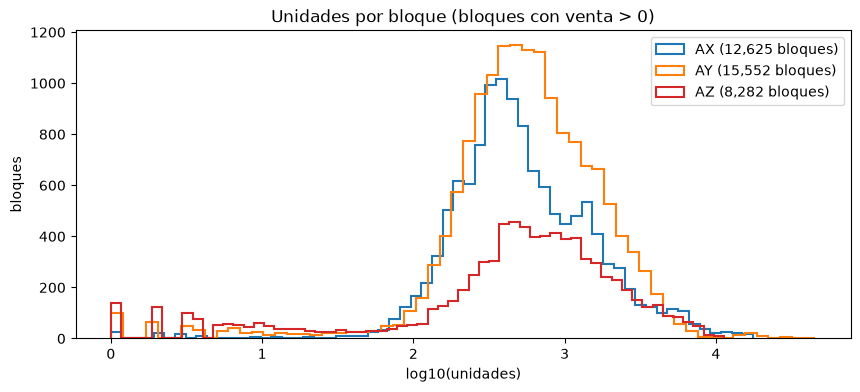

,item_id,block,start_d,end_d,start_date,end_date,days_with_data,units,chain_units
0,FOODS_3_586,1,122,149,2011-05-30,2011-06-26,28,14983.0,711650.0
1,FOODS_3_586,2,150,177,2011-06-27,2011-07-24,28,15156.0,735634.0
2,FOODS_3_586,3,178,205,2011-07-25,2011-08-21,28,17599.0,752978.0
3,FOODS_3_586,4,206,233,2011-08-22,2011-09-18,28,16698.0,749675.0
4,FOODS_3_586,5,234,261,2011-09-19,2011-10-16,28,16198.0,806458.0


In [118]:
import matplotlib.pyplot as plt

seg = blocks["item_id"].map(targets.set_index("item_id")["cell"])
display(blocks.groupby(seg)["units"].describe(percentiles=[0.05, 0.5, 0.95]).round(1))

fig, ax = plt.subplots(figsize=(10, 4))
for cell, color in zip(["AX", "AY", "AZ"], ["#1f77b4", "#ff7f0e", "#d62728"]):
    s = blocks.loc[(seg == cell) & (blocks["units"] > 0), "units"]
    ax.hist(np.log10(s), bins=60, histtype="step", linewidth=1.5, color=color, label=f"{cell} ({(seg == cell).sum():,} bloques)")
ax.set(title="Unidades por bloque (bloques con venta > 0)", xlabel="log10(unidades)", ylabel="bloques")
ax.legend()
plt.show()
display(blocks.head())

### 4.2 · Bloques no válidos: valor del bloque anterior

**Qué hace:** `fill_invalid_blocks` marca como no válido un bloque por dos motivos (`invalid_reason`):
- **`min_days`:** tiene menos días observados que el `min_days` congelado del artículo (nb 03), incluidos los bloques sin ningún día con dato. Casi todo el bloque cae en un quiebre.
- **`low_units`:** pasó `min_days`, pero sus unidades no llegan al 10 % de su referencia (`low_block_share = 0.1`). Es un quiebre que unas ventas sueltas de 1 a 3 unidades escondieron: cortan las rachas de ceros y el bloque queda con días "observados". Ejemplo: HOUSEHOLD_1_327, bloque 40, 10 días observados y 13 unidades frente a unas 2.000 normales. La referencia es la mediana de sus últimos 6 bloques válidos (`low_block_window = 6`, un semestre); en los primeros 6 bloques, la mediana de los bloques válidos de esos 6, que siempre están antes de la ventana de backtesting (sin fuga). El bloque 1 del artículo no se evalúa: un lanzamiento que arranca vendiendo poco no es un quiebre.

El bloque no válido toma el valor del bloque anterior del mismo artículo (forward fill) y queda marcado en `imputed`.

**Decisión (usuario, constitución 6.0.0):**
- Con el valor anterior, el ratio del bloque no válido vale 1 ("no cambió la tendencia") y el bloque siguiente se compara contra el último bloque válido, que es el punto de comparación real.
- La serie queda completa y continua; se miden todos los bloques de la ventana de backtesting y del test.
- `min_days` se usa como criterio de bloque válido porque ya está justificado y congelado en el nb 03 (R5).
- **10 % (decisión del usuario):** la idea es capturar los quiebres sin dañar la baja demanda real. Un bloque que vende menos de la décima parte de su nivel reciente es casi seguro un quiebre. Frente al 20 %, marca 242 bloques menos (la zona dudosa entre 10 % y 20 %, sobre todo en AZ) y deja 33 ratios > 10 en el train en vez de 17. Con 5 % quedarían 71, y con la mediana (100 %) se marcaría más de la mitad de los bloques.
- **6 bloques (decisión del usuario):** las series se parecen más a sus periodos recientes que al mismo periodo del año anterior (estabilidad, nb 02). Con 3, 6 o 13 bloques el resultado es casi igual; 6 no se mueve por un solo bloque raro y coincide con la ventana de 6 de la 6a.
- Si los primeros bloques de un artículo no son válidos (lanzamiento con pocos días), no hay valor que arrastrar: se eliminan y la serie empieza en el primer bloque válido. Por eso este paso va antes de la partición: el mínimo de 39 bloques y los 13 de test se cuentan sobre la serie ya recortada.

**Revisar:** cuántos bloques se completan, cuántos bloques iniciales se eliminan, que no quede ningún NaN, y un ejemplo.

In [119]:
blocks_valid = fill_invalid_blocks(blocks, targets.set_index("item_id")["min_days"],
                                   cfg["features"]["low_block_share"], cfg["features"]["low_block_window"])

In [120]:
b = blocks_valid
assert b["units"].notna().all() and (b["units"] > 0).all(), "sin NaN ni ceros"
assert b["item_id"].nunique() == blocks["item_id"].nunique()
assert (b.groupby("item_id")["block"].diff().dropna() == 1).all(), "bloques contiguos"
first = b.groupby("item_id").cumcount() == 0
assert not b.loc[first, "imputed"].any(), "cada serie empieza en un bloque válido"
prev = b.groupby("item_id")["units"].shift(1)
assert (b.loc[b["imputed"], "units"] == prev[b["imputed"]]).all(), "el bloque no válido toma el valor del anterior"
assert (b.groupby("item_id")["block"].max() == blocks.groupby("item_id")["block"].max()).all(), "el final de la serie no cambia"

dropped = blocks.groupby("item_id").size() - b.groupby("item_id").size()
print(f"bloques no válidos completados: {int(b['imputed'].sum())} en {b.loc[b['imputed'], 'item_id'].nunique()} artículos"
      f" · de ellos sin ningún día con dato: {int((b['imputed'] & (b['days_with_data'] == 0)).sum())}")
display(b.loc[b["imputed"], "invalid_reason"].value_counts().rename("bloques completados").to_frame())
assert set(b["invalid_reason"]) <= {"", "min_days", "low_units"} and (b["imputed"] == (b["invalid_reason"] != "")).all()
print(f"bloques iniciales no válidos eliminados: {int(dropped.sum())} en {int((dropped > 0).sum())} artículos")
display(dropped[dropped > 0].value_counts().sort_index().rename("artículos").rename_axis("bloques eliminados").to_frame().T)
display(b[(b["item_id"] == "FOODS_3_404") & b["block"].between(49, 55)][["item_id", "block", "days_with_data", "units", "imputed", "invalid_reason"]])
display(b[(b["item_id"] == "HOUSEHOLD_1_327") & b["block"].between(38, 43)][["item_id", "block", "days_with_data", "units", "imputed", "invalid_reason"]])

bloques no válidos completados: 2175 en 302 artículos · de ellos sin ningún día con dato: 587


,bloques completados
invalid_reason,
min_days,1215
low_units,960


bloques iniciales no válidos eliminados: 96 en 50 artículos


bloques eliminados,1,2,3,4,10
artículos,31,6,5,7,1


,item_id,block,days_with_data,units,imputed,invalid_reason
13996,FOODS_3_404,49,28,1424.0,False,
13997,FOODS_3_404,50,28,1979.0,False,
13998,FOODS_3_404,51,19,514.0,False,
13999,FOODS_3_404,52,1,514.0,True,min_days
14000,FOODS_3_404,53,21,2789.0,False,
14001,FOODS_3_404,54,28,4329.0,False,
14002,FOODS_3_404,55,28,4243.0,False,


,item_id,block,days_with_data,units,imputed,invalid_reason
31021,HOUSEHOLD_1_327,38,28,2061.0,False,
31022,HOUSEHOLD_1_327,39,21,542.0,False,
31023,HOUSEHOLD_1_327,40,10,542.0,True,low_units
31024,HOUSEHOLD_1_327,41,15,449.0,False,
31025,HOUSEHOLD_1_327,42,28,1695.0,False,
31026,HOUSEHOLD_1_327,43,28,1967.0,False,


### 4.2a · Primer bloque incompleto: la serie empieza en el bloque siguiente

**Problema (Etapa 11, ratios > 2 por segmento):** 72 de los 130 ratios > 2 de arranque están en el bloque 2 (25 de los 29 de AX). En esos artículos el primer bloque está incompleto: el artículo empezó a venderse a mitad de bloque o tuvo días enmascarados (mediana 14 días con datos de 28) y vende alrededor del 27 % de su nivel, mientras el bloque 2 ya está al 89 %. No es una rampa: es medio mes de venta. Pasa `min_days` (4 a 9 días) y la 4.2 no lo puede completar porque no tiene bloque anterior.
**Entradas:** `blocks_valid` (4.2) y `MIN_BLOCKS = 39` (constitución 4.0.0, Principio VI; lo usa la 4.3).
**Salidas:** `blocks_valid` sin los primeros bloques incompletos.

**Decisión (usuario):**
- Si el primer bloque de un artículo tiene menos de 28 días con datos (bloque completo), se quita y la serie empieza en el siguiente bloque válido. Si los bloques que siguen eran no válidos (4.2), copiaron el valor del bloque incompleto y también se quitan, igual que la 4.2 quita los bloques iniciales no válidos.
- **Por qué 28 y no 14 (R4):** el ratio del bloque 2 sale inflado en todos los tramos con menos de 28 días, aun con 22 a 27 días (mediana 1,21; 12 % > 2), frente a 1,03 y 1 % > 2 con el bloque completo. La celda de chequeo recalcula la tabla.
- **Excepción:** si al quitarlo el artículo quedaría con menos de 39 bloques, se conserva, para no sacarlo de la modelación. Son FOODS_3_499 y HOUSEHOLD_1_338 (AX): series estables, sin ratios > 2 en la ventana ni en test; el ratio del bloque 2 cae en train, antes de la ventana, y si pasa de 2 lo vacía la 6a.
- No se revisa si el nuevo primer bloque también está incompleto: el bloque 2 ya está prácticamente en su nivel.
- Va antes de la 4.2b, para que la mediana de referencia de los bloques atípicos no use el bloque incompleto, y antes de la partición (4.3), que cuenta los 39 bloques sobre la serie ya recortada.

**Revisar:** cuántos artículos pierden el primer bloque y cuántos se conservan por la excepción, por segmento; la tabla de los 28 días; los ratios > 2 del arranque antes y después.

In [121]:
from src.features import drop_partial_first_block


In [122]:
MIN_BLOCKS = 39   # constitución 4.0.0, Principio VI (también lo usa la 4.3)
blocks_42 = blocks_valid
blocks_42a = drop_partial_first_block(blocks_42, MIN_BLOCKS)   # entrada de la 4.2b y de la regla causal de la 4.4
blocks_valid = blocks_42a


In [123]:
cell_of = targets.set_index("item_id")["cell"]
before, after = blocks_42.sort_values(["item_id", "block"]), blocks_42a
lost = before.groupby("item_id").size() - after.groupby("item_id").size()
first_42 = before.groupby("item_id").head(1).set_index("item_id")
assert after["item_id"].nunique() == before["item_id"].nunique()
assert (first_42.loc[lost[lost > 0].index, "days_with_data"] < 28).all(), "solo se recortan series con el primer bloque incompleto"
removed = before.merge(after[["item_id", "block"]], how="left", indicator=True).query("_merge == 'left_only'")
assert (removed.groupby("item_id").cumcount().gt(0) <= removed["imputed"]).all(), "tras el primero, solo se quitan bloques no válidos"
assert not after.groupby("item_id").head(1)["imputed"].any(), "cada serie empieza en un bloque válido"
assert (after.groupby("item_id")["block"].diff().dropna() == 1).all(), "bloques contiguos"
assert (after.groupby("item_id")["block"].max() == before.groupby("item_id")["block"].max()).all(), "el final de la serie no cambia"
kept = first_42.index[(first_42["days_with_data"] < 28) & (lost == 0).reindex(first_42.index)]
n_before = before.groupby("item_id").size()
assert (n_before[kept] - 1 < MIN_BLOCKS).all(), "solo se conserva un incompleto si quitarlo deja menos de 39 bloques"

inc = first_42["days_with_data"] < 28
display(pd.DataFrame({"artículos": first_42.groupby(cell_of)["days_with_data"].size(),
                      "primer bloque incompleto": inc.groupby(cell_of).sum(),
                      "se recorta": (lost > 0).groupby(cell_of).sum(), "bloques quitados": lost.groupby(cell_of).sum(),
                      "se conserva (excepción de 39 bloques)": pd.Series(first_42.index.isin(kept), index=first_42.index).groupby(cell_of).sum()}))
display(first_42.loc[kept, ["block", "days_with_data", "units"]].assign(cell=cell_of[kept], bloques=n_before[kept]))

# Justificación de los 28 días: ratio del bloque 2 según los días con datos del primer bloque (antes del recorte).
r2 = before.groupby("item_id")["units"].nth(1).set_axis(first_42.index) / first_42["units"]
tramo = pd.cut(first_42["days_with_data"], [0, 7, 14, 21, 27, 28])
display(pd.DataFrame({"artículos": r2.groupby(tramo, observed=True).size(),
                      "ratio del bloque 2 (mediana)": r2.groupby(tramo, observed=True).median().round(2),
                      "% ratio > 2": (r2.gt(2).groupby(tramo, observed=True).mean() * 100).round(1)})
        .rename_axis("días con datos del primer bloque"))

# Ratios > 2 de arranque (posiciones 2 a 7) antes y después.
def start_hi(b):
    b = b.sort_values(["item_id", "block"]); g = b.groupby("item_id")
    r, pos = b["units"] / g["units"].shift(1), g.cumcount() + 1
    return int(((r > 2) & pos.between(2, 7)).sum()), int(((r > 2) & (pos == 2)).sum())
display(pd.DataFrame([start_hi(before), start_hi(after)], columns=["ratios > 2 en posiciones 2–7", "en la posición 2"],
                     index=["antes (4.2)", "después (4.2a)"]))


,artículos,primer bloque incompleto,se recorta,bloques quitados,se conserva (excepción de 39 bloques)
cell,,,,,
AX,207,51,45,45,6
AY,251,78,75,100,3
AZ,134,42,37,48,5


,block,days_with_data,units,cell,bloques
item_id,,,,,
FOODS_3_002,32,17,1069.0,AX,34
FOODS_3_282,28,5,110.0,AY,38
FOODS_3_370,36,25,119.0,AZ,30
FOODS_3_499,27,24,1739.0,AX,39
FOODS_3_636,28,7,37.0,AZ,38
HOBBIES_1_155,28,19,96.0,AX,38
HOBBIES_1_158,29,16,2.0,AZ,37
HOBBIES_1_241,34,4,12.0,AX,32
HOUSEHOLD_1_102,36,10,53.0,AY,30


,artículos,ratio del bloque 2 (mediana),% ratio > 2
días con datos del primer bloque,,,
"(0, 7]",23,6.65,87.0
"(7, 14]",38,2.74,60.5
"(14, 21]",57,1.68,43.9
"(21, 27]",53,1.22,11.3
"(27, 28]",421,1.03,1.2


,ratios > 2 en posiciones 2–7,en la posición 2
antes (4.2),146,79
después (4.2a),74,20


### 4.2b · Bloques atípicos: válidos, pero con una caída que el artículo no repite

**Problema (Etapa 11):** hay bloques que pasan `min_days` y `low_units` y aun así están deprimidos: un quiebre parcial o una caída puntual de la demanda. El bloque siguiente compara contra ese valor bajo y su ratio sale inflado; además, el seasonal naive repite la caída 13 bloques después. La causa está en las unidades, así que se corrige aquí, antes del ratio y del feature engineering.
**Entradas:** `blocks_valid` (4.2 y 4.2a) y `params.toml [features]`: `atypical_level = 0.5`, `atypical_min_ref = 3`, `atypical_years = 3` y `low_block_window = 6` (con historial).
**Salidas:** `blocks_valid` con las unidades corregidas, `units_observed` (las de antes de esta regla) e `invalid_reason` = `atypical` o `atypical_first_year` en los bloques completados (`imputed` = True).

**Decisión (usuario), para todos los artículos y bloques, por artículo y en orden:**
- **Nivel del bloque** = unidades ÷ mediana de sus últimos 6 bloques válidos (la ventana de `low_units`). Exige 3 bloques válidos: con 1 o 2, la mediana es prácticamente un solo bloque. El bloque 1 no se evalúa.
- **Deprimido:** nivel < 50 %. Se mira el mismo periodo en los 3 años anteriores (todo el train disponible):
  - **se repite** en algún año anterior → es un patrón del artículo y no se toca;
  - **no se repite → atípico:** toma la **mediana reciente × factor**, con factor = **mediana de los niveles de ese periodo en los años anteriores disponibles, con tope 1** (opción 1, decisión del usuario). La mediana reciente trae el nivel actual (la tendencia); copiar las unidades del año anterior ignoraría si el artículo creció o cayó. La mediana de los años evita que un solo año raro mande, y el tope impide que el valor completado supere el nivel actual y cree un salto: con solo el año más reciente y sin tope, 29 ratios > 2 los creaba la propia regla (FOODS_2_198, bloque 27: 91 unidades observadas completadas a 1.727, con un nivel normal de ~400). El tope elimina 30 de esos saltos y crea 3 (el bloque completado queda más bajo y sube el ratio del siguiente), que vacía la 6a;
  - **sin año anterior** (primer año del artículo) → toma el valor del bloque anterior, como la regla de la 4.2.
- La referencia sigue con las unidades **observadas**, también las del bloque atípico: un bloque aislado casi no la mueve y una caída que persiste la baja, así que la regla se detiene sola ante un cambio de nivel real.
- Los bloques no válidos de la 4.2 vuelven a tomar el valor del bloque anterior ya corregido.
- Solo usa bloques anteriores al evaluado: no hay fuga. Se aplica también al test, igual que la 4.2.
- **Por qué 50 % (R4):** por debajo del 50 % de su nivel, el ratio siguiente supera 2 en el 20–38 % de los casos; por encima, en el 6 % o menos. Solo el 3,2 % de los bloques queda por debajo. En train estricto (calculado aparte con la partición de la 4.3) da lo mismo en lo esencial: 18–35 % frente a 4 % o menos. La celda de chequeo recalcula la tabla con todas las series (la partición todavía no existe).
- Los ratios > 2 que todavía queden (sobre todo arranques y subidas reales) los deja vacíos el tratamiento de la 6a.

**Revisar:** cuántos bloques se completan y de qué tipo, por segmento; que el valor completado no sea desmedido; la tabla del 50 %; y ejemplos.

In [124]:
from src.features import fill_atypical_blocks

In [125]:
blocks_valid = fill_atypical_blocks(blocks_42a, cfg["features"]["atypical_level"], cfg["features"]["low_block_window"],
                                    cfg["features"]["atypical_min_ref"], cfg["features"]["atypical_years"])

In [126]:
b = blocks_valid.sort_values(["item_id", "block"])
NEW = {"atypical", "atypical_first_year"}
assert b["units"].notna().all() and (b["units"] > 0).all(), "sin NaN ni ceros"
assert (b.groupby("item_id")["block"].diff().dropna() == 1).all(), "bloques contiguos"
assert set(b["invalid_reason"]) <= {"", "min_days", "low_units"} | NEW and (b["imputed"] == (b["invalid_reason"] != "")).all()
valid = b["invalid_reason"] == ""
assert (b.loc[valid, "units"] == b.loc[valid, "units_observed"]).all(), "los bloques válidos no cambian"
prev = b.groupby("item_id")["units"].shift(1)
old = b["invalid_reason"].isin(["min_days", "low_units", "atypical_first_year"])
assert (b.loc[old, "units"] == prev[old]).all(), "no válidos de la 4.2 y del primer año: valor del bloque anterior ya corregido"

# Cuántos y dónde, por segmento.
cell_of = targets.set_index("item_id")["cell"]
new = b[b["invalid_reason"].isin(NEW)]
display(pd.crosstab(new["item_id"].map(cell_of), new["invalid_reason"], margins=True, margins_name="total")
        .join(b.groupby(b["item_id"].map(cell_of))["item_id"].nunique().rename("artículos")).join(
        new.groupby(new["item_id"].map(cell_of))["item_id"].nunique().rename("artículos con bloques completados")))
factor = new["units"] / new["units_observed"]
print(f"valor completado ÷ observado: mediana {factor.median():.2f} · p95 {factor.quantile(0.95):.2f} · máximo {factor.max():.2f}"
      f" · bloques completados por artículo: máximo {new.groupby('item_id').size().max()}")

# Justificación del 50 %: nivel de los bloques válidos y ratio siguiente, con unidades observadas (todas las series;
# el split aún no existe: la 4.3 lo define).
g = b.groupby("item_id")
ref = g["units_observed"].transform(lambda s: s.shift(1).rolling(cfg["features"]["low_block_window"], min_periods=cfg["features"]["atypical_min_ref"]).median())
lvl = b["units_observed"] / ref
next_ratio = g["units_observed"].shift(-1) / b["units_observed"]
ok = lvl.notna() & b["invalid_reason"].isin(["", "atypical", "atypical_first_year"])
bins = pd.cut(lvl[ok], [0, 0.3, 0.5, 0.7, 0.9, 1.1, np.inf], right=False)
display(pd.DataFrame({"bloques": bins.value_counts(sort=False),
                      "% de los bloques": (bins.value_counts(sort=False, normalize=True) * 100).round(2),
                      "% con ratio siguiente > 2": (next_ratio[ok].gt(2).groupby(bins, observed=False).mean() * 100).round(1)})
        .rename_axis("nivel del bloque (aprox., referencia con todos los válidos observados)"))

# Ratio antes y después de la regla (todas las series).
ratio_before = b["units_observed"] / g["units_observed"].shift(1)
ratio_after = b["units"] / g["units"].shift(1)
display(pd.DataFrame({"antes": [int(ratio_before.between(2, 10, inclusive="right").sum()), int((ratio_before > 10).sum()), int((ratio_before < 0.5).sum()), round(ratio_before.quantile(0.99), 2)],
                      "después": [int(ratio_after.between(2, 10, inclusive="right").sum()), int((ratio_after > 10).sum()), int((ratio_after < 0.5).sum()), round(ratio_after.quantile(0.99), 2)]},
                     index=["ratios 2–10", "ratios > 10", "ratios < 0,5", "percentil 99"]))
for item, lo, hi in [("HOBBIES_1_367", 37, 42), ("FOODS_2_019", 23, 27)]:
    display(b[(b["item_id"] == item) & b["block"].between(lo, hi)][["item_id", "block", "days_with_data", "units_observed", "units", "invalid_reason"]])

,atypical,atypical_first_year,total,artículos,artículos con bloques completados
item_id,,,,,
AX,87,16,103,207.0,62.0
AY,315,95,410,251.0,171.0
AZ,300,137,437,134.0,122.0
total,702,248,950,NaN,NaN


valor completado ÷ observado: mediana 2.65 · p95 7.84 · máximo 15.38 · bloques completados por artículo: máximo 9


,bloques,% de los bloques,% con ratio siguiente > 2
"nivel del bloque (aprox., referencia con todos los válidos observados)",,,
"[0.0, 0.3)",383,1.19,38.4
"[0.3, 0.5)",661,2.05,20.3
"[0.5, 0.7)",1782,5.52,6.3
"[0.7, 0.9)",6559,20.33,0.7
"[0.9, 1.1)",12749,39.51,0.3
"[1.1, inf)",10132,31.40,0.6


,antes,después
ratios 2–10,719.00,336.00
ratios > 10,34.00,15.00
"ratios < 0,5",675.00,244.00
percentil 99,3.12,1.99


,item_id,block,days_with_data,units_observed,units,invalid_reason
24886,HOBBIES_1_367,37,28,176.0,176.0,
24887,HOBBIES_1_367,38,28,127.0,127.0,
24888,HOBBIES_1_367,39,15,22.0,196.0,atypical
24889,HOBBIES_1_367,40,11,59.0,183.5,atypical
24890,HOBBIES_1_367,41,28,172.0,172.0,
24891,HOBBIES_1_367,42,28,183.0,183.0,


,item_id,block,days_with_data,units_observed,units,invalid_reason
2745,FOODS_2_019,23,22,1271.0,1271.000000,
2746,FOODS_2_019,24,26,898.0,898.000000,
2747,FOODS_2_019,25,17,327.0,1352.527287,atypical
2748,FOODS_2_019,26,28,1344.0,1344.000000,
2749,FOODS_2_019,27,28,1380.0,1380.000000,


### 4.3 · Partición por artículo e historial mínimo

**Qué hace:** `assign_windows` numera los bloques de cada artículo (serie ya recortada en la 4.2 y la 4.2a) (`pos` = 1, 2, …) y cuenta desde el final: los 13 últimos son `test` y el resto `train`; de train, los 13 bloques anteriores al test se marcan `backtest = True`. Excluye a los artículos con menos de 39 bloques.
**Revisar:** artículos que se modelan y excluidos (con su gasto de train); que cada artículo tenga exactamente 13 bloques de test, 13 de ventana de backtesting y al menos 13 de train antes de la ventana; y los artículos cuyo test no es el año 5 (su test cae en fechas que para otros son train: se documenta, constitución 4.0.0).

In [127]:
TEST_BLOCKS, VAL_BLOCKS = 13, 13   # constitución 4.0.0, Principio VI (MIN_BLOCKS = 39 viene de la 4.2a)
blocks_43, excluded = assign_windows(blocks_valid, TEST_BLOCKS, VAL_BLOCKS, MIN_BLOCKS)
blocks_model = blocks_43   # la 4.4 parte de blocks_43

In [128]:
cell_of = targets.set_index("item_id")["cell"]
share_of = targets.set_index("item_id")["spend_share"]
kept_ids = blocks_model["item_id"].unique()
display(pd.DataFrame({
    "artículos": [len(kept_ids), len(excluded)],
    "AX": [(cell_of[kept_ids] == "AX").sum(), (cell_of[excluded["item_id"]] == "AX").sum()],
    "AY": [(cell_of[kept_ids] == "AY").sum(), (cell_of[excluded["item_id"]] == "AY").sum()],
    "AZ": [(cell_of[kept_ids] == "AZ").sum(), (cell_of[excluded["item_id"]] == "AZ").sum()],
    "% gasto de train": [share_of[kept_ids].sum() * 100, share_of[excluded["item_id"]].sum() * 100],
}, index=["se modelan", "excluidos (< 39 bloques)"]).round(2))
display(excluded.assign(cell=excluded["item_id"].map(cell_of)))

part = np.where(blocks_model["split"] == "test", "test", np.where(blocks_model["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
per_item = blocks_model.assign(part=part).pivot_table(index="item_id", columns="part", values="block", aggfunc="size")
assert (per_item["test"] == TEST_BLOCKS).all() and (per_item["train: ventana de backtesting"] == VAL_BLOCKS).all()
assert (per_item["train: antes de la ventana"] >= MIN_BLOCKS - TEST_BLOCKS - VAL_BLOCKS).all()
assert not (blocks_model["backtest"] & (blocks_model["split"] == "test")).any()
assert len(kept_ids) + len(excluded) == 592
display(blocks_model.assign(part=part).groupby("part").agg(bloques=("block", "size"), no_validos_completados=("imputed", "sum")))
display(per_item.describe().round(1).T)
display(blocks_model.assign(part=part).groupby(["split", "part"]).agg(filas=("item_id", "size"), primer_bloque=("block", "min"), último_bloque=("block", "max")))

test_start = blocks_model[blocks_model["split"] == "test"].groupby("item_id")["block"].min()
off_y5 = test_start[test_start != 53]
print(f"artículos cuyo test no es el año 5 (bloques 53–65): {len(off_y5)}")
display(blocks_model.assign(part=part)[blocks_model["item_id"].isin(off_y5.index)].groupby(["item_id", "part"])
        .agg(desde=("start_date", "min"), hasta=("end_date", "max"), bloques=("block", "size")).unstack("part"))

,artículos,AX,AY,AZ,% gasto de train
se modelan,579,203,248,128,58.87
excluidos (< 39 bloques),13,4,3,6,1.01


,item_id,n_blocks,reason,cell
0,FOODS_3_002,34,menos de 39 bloques de ciclo de vida,AX
1,FOODS_3_077,33,menos de 39 bloques de ciclo de vida,AZ
2,FOODS_3_282,38,menos de 39 bloques de ciclo de vida,AY
3,FOODS_3_370,30,menos de 39 bloques de ciclo de vida,AZ
4,FOODS_3_636,38,menos de 39 bloques de ciclo de vida,AZ
5,HOBBIES_1_155,38,menos de 39 bloques de ciclo de vida,AX
6,HOBBIES_1_158,37,menos de 39 bloques de ciclo de vida,AZ
7,HOBBIES_1_241,32,menos de 39 bloques de ciclo de vida,AX
8,HOUSEHOLD_1_102,30,menos de 39 bloques de ciclo de vida,AY
9,HOUSEHOLD_1_106,30,menos de 39 bloques de ciclo de vida,AZ


,bloques,no_validos_completados
part,,
test,7527,678
train: antes de la ventana,20670,1574
train: ventana de backtesting,7527,791


,count,mean,std,min,25%,50%,75%,max
part,,,,,,,,
test,579.0,13.0,0.0,13.0,13.0,13.0,13.0,13.0
train: antes de la ventana,579.0,35.7,6.1,13.0,35.0,39.0,39.0,39.0
train: ventana de backtesting,579.0,13.0,0.0,13.0,13.0,13.0,13.0,13.0


filas  primer_bloque  último_bloque
split part                                                              
test  test                            7527             46             65
train train: antes de la ventana     20670              1             39
      train: ventana de backtesting   7527             33             52

artículos cuyo test no es el año 5 (bloques 53–65): 3


desde                             \
part                  test train: antes de la ventana   
item_id                                                 
FOODS_3_441     2014-11-10                 2012-03-05   
HOUSEHOLD_1_366 2015-03-30                 2011-08-22   
HOUSEHOLD_1_427 2015-04-27                 2011-08-22   

                                                   hasta  \
part            train: ventana de backtesting       test   
item_id                                                    
FOODS_3_441                        2013-11-11 2015-11-08   
HOUSEHOLD_1_366                    2014-03-31 2016-03-27   
HOUSEHOLD_1_427                    2014-04-28 2016-04-24   

                                                                          \
part            train: antes de la ventana train: ventana de backtesting   
item_id                                                                    
FOODS_3_441                     2013-11-10                    2014-11-09   
HOUSEHOLD_1_366                 2014-03-30                    2015-03-29   
HOUSEHOLD_1_427                 2014-04-27                    2015-04-26   

                bloques                             \
part               test train: antes de la ventana   
item_id                                              
FOODS_3_441          13                         22   
HOUSEHOLD_1_366      13                         34   
HOUSEHOLD_1_427      13                         35   

                                               
part            train: ventana de backtesting  
item_id                                        
FOODS_3_441                                13  
HOUSEHOLD_1_366                            13  
HOUSEHOLD_1_427                            13

### 4.4 · Casos atípicos: imputación dirigida en la historia y regla causal en ventana y test (B+)

**Problema (diagnóstico por segmento, tras la 4.2b):** quedaban 576 ratios extremos (> 2 o < 0,5). Separados por causa: 188 estructurales (el nivel cambia y se mantiene; no se tocan), 294 atípicos (quiebre, pico o caída de un bloque, bloque deprimido que la 4.2b no corrigió), 15 propagados por las reglas y 79 de arranque.
**Entradas:** `blocks_42a` (4.2a), `blocks_43` (4.3) y `params.toml [features]` (con historial): `atypical_level_masked = 0.8`, `atypical_pattern_years = 2`, `atypical_refill_level = 0.8`, `case_low_level = 0.8`, `case_high_level = 1.25`, `case_masked_days = 14`, `case_start_blocks = 7`.
**Salidas:** `blocks_model` con las unidades corregidas (`invalid_reason` = `case_history` en la historia; `atypical` y demás en la ventana y el test), `cases` (clasificación) y `blocks_causal`.

**Decisión (usuario, opción B+):**
- **Dónde se puede dirigir una regla:** saber si un bloque es un caso exige ver el ratio de t (y a veces t+1). En la **historia** (train antes de la ventana) eso no es fuga: todos los folds entrenan con ella completa. En la **ventana y el test** sí lo sería, porque es lo que se pronostica: ahí solo vale una regla **causal** (que solo mira el pasado).
- **Historia: imputación directa del bloque culpable** de cada caso atípico o propagado (`impute_history_cases`), con la mediana de los 6 bloques válidos anteriores. El culpable sale de la clasificación (`classify_extreme_ratios`): t (pico o caída de un bloque), t−1 y la cadena de no válidos que lo copió (denominador bajo), t y los bloques siguientes con quiebre (caída con quiebre que persiste) o los bloques con quiebre antes de una recuperación. Solo si el caso y t+1 están en la historia; nunca toca bloques de un caso estructural.
- **Ventana y test: la 4.2b con tres extensiones causales** (`fill_atypical_blocks` sobre `blocks_42a`; `replace_after_history`):
  - **E1:** con días enmascarados, deprimido = < 80 % (un quiebre parcial deja el bloque entre 50 y 80 %).
  - **E7:** la caída es patrón solo si se repite en 2 de los años anteriores (con 1 bastaba una coincidencia).
  - **E8:** el no válido que sigue a un bloque < 80 % de su nivel toma la mediana reciente en vez de copiarlo.
- **Arranque (E11, en la 6a):** sin historia para imputar; la 6a deja vacío también el ratio < 0,5 en las posiciones ≤ 7.
- **Por qué estas reglas y no otras (R4; diagnóstico fuera del notebook, conteo y boosting proxy con 13 folds y 3 semillas):**

  | Estrategia descartada | Motivo |
  |---|---|
  | Umbral de la 4.2b en 0,7 u 0,8 para todos los bloques | 149–281 ratios extremos nuevos; toca 42–48 estructurales |
  | Versión de la 4.2b para picos (nivel > 2) | sin t+1 no distingue un pico de un cambio de nivel: toca 50 estructurales, 132 extremos nuevos |
  | Referencia congelada durante el quiebre (E2) | suma poco a E1 y triplica los estructurales tocados |
  | La 6a vacía todos los ratios < 0,5 | empeora el pronóstico (+0,007 de RMSSE): saca del ajuste caídas reales |
  | Reglas causales también en la historia | tocan 262 bloques fuera de los casos sin mejorar el pronóstico |

- **Resultado esperado** (casos atípicos y propagados, sin arranque): 309 → 122 (AX 22 → 6, AY 126 → 39, AZ 161 → 77). Pronóstico (proxy, bloques de la ventana que ninguna variante modifica): RMSSE medio 0,5400 → 0,5344 (Δ −0,0055, IC 95 % [−0,0115; +0,0006]); AX −0,006 y AY −0,012 (significativos); AZ +0,007 con un intervalo de [−0,014; +0,030]. **AZ se vigila en las Etapas 12–13**: si se confirma que empeora, la imputación de la historia se puede desactivar para AZ.
- **Costo:** en la ventana y el test la regla causal toca ≈ 435 bloques que no son casos (casi todos quiebres parciales leves: 388 de 433 con días enmascarados) y 11 caídas estructurales (por E7).
- Los 78 arranques quedan en las unidades, pero fuera del ajuste (6a y E11). Los umbrales 0,8 / 1,25 / 14 días son de la clasificación; el detalle de cada uno está en `params.toml` y en su historial.

**Revisar:** que la historia solo cambie en los bloques culpables y la ventana y el test coincidan con la regla causal; casos por grupo y segmento antes y después; bloques tocados por tramo; ejemplos.

In [129]:
from src.features import classify_extreme_ratios, impute_history_cases, replace_after_history


In [130]:
blocks_causal = fill_atypical_blocks(blocks_42a, cfg["features"]["atypical_level"], cfg["features"]["low_block_window"], cfg["features"]["atypical_min_ref"],
                                     cfg["features"]["atypical_years"], level_masked=cfg["features"]["atypical_level_masked"],
                                     pattern_years=cfg["features"]["atypical_pattern_years"], refill_level=cfg["features"]["atypical_refill_level"])


In [131]:
cases = classify_extreme_ratios(blocks_43, cfg["features"]["atypical_level"], cfg["features"]["case_low_level"],
                                cfg["features"]["case_high_level"], cfg["features"]["case_masked_days"],
                                cfg["features"]["case_start_blocks"], window=cfg["features"]["low_block_window"],
                                min_ref=cfg["features"]["atypical_min_ref"])


In [132]:
blocks_model = replace_after_history(impute_history_cases(blocks_43, cases, cfg["features"]["low_block_window"],
                                                         cfg["features"]["atypical_min_ref"]), blocks_causal)


In [133]:
k = ["item_id", "block"]
before, after = blocks_43.sort_values(k).reset_index(drop=True), blocks_model.sort_values(k).reset_index(drop=True)
assert before[k].equals(after[k]) and after["units"].notna().all() and (after["units"] > 0).all()
rest = (after["split"] == "test") | after["backtest"]
causal_u = blocks_causal.set_index(k)["units"].reindex(pd.MultiIndex.from_frame(after.loc[rest, k])).to_numpy()
assert np.allclose(after.loc[rest, "units"], causal_u), "ventana y test = regla causal"
changed_hist = ~rest & ~np.isclose(before["units"], after["units"])
assert (after.loc[changed_hist, "invalid_reason"] == "case_history").all(), "en la historia solo cambian los bloques culpables"
assert (after.loc[~rest & (after["invalid_reason"] == "case_history"), "split"] == "train").all()

# Casos por grupo: total, en qué tramo caen y cuántos siguen siendo extremos (ratio con las unidades nuevas).
cell_of = targets.set_index("item_id")["cell"]
u_new = after.set_index(k)["units"]
prev_key = pd.MultiIndex.from_arrays([cases["item_id"], cases["block"] - 1])
r_new = u_new.reindex(pd.MultiIndex.from_frame(cases[k])).to_numpy() / u_new.reindex(prev_key).to_numpy()
c = cases.assign(cell=cases["item_id"].map(cell_of), remains=~((r_new >= 0.5) & (r_new <= 2)),
                 tramo=after.set_index(k).reindex(pd.MultiIndex.from_frame(cases[k])).pipe(
                     lambda d: np.where(d["split"] == "test", "test", np.where(d["backtest"], "ventana", "historia"))))
label = c["group"].where(c["group"] != "atipico", "atipico: " + c["subgroup"])
summary = pd.concat({"teníamos": pd.crosstab(label, c["cell"], margins=True, margins_name="total"),
                     "quedan": pd.crosstab(label[c["remains"]], c.loc[c["remains"], "cell"], margins=True, margins_name="total")}, axis=1).fillna(0).astype(int)
display(summary.swaplevel(axis=1).sort_index(axis=1, level=0))
nc = c[~c["group"].isin(["estructural", "arranque"])]
display(nc.groupby("cell").agg(teníamos=("remains", "size"), quedan=("remains", "sum"))
        .assign(**{"reducción %": lambda d: (100 * (1 - d["quedan"] / d["teníamos"])).round(0)})
        .rename_axis("atípicos y propagados"))
display(pd.crosstab(nc.loc[nc["remains"], "cell"], nc.loc[nc["remains"], "tramo"]).rename_axis("quedan por tramo"))

# Bloques tocados por tramo y motivo.
tr = np.where(after["split"] == "test", "test", np.where(after["backtest"], "ventana", "historia"))
ch = ~np.isclose(before["units"], after["units"])
display(pd.crosstab(after.loc[ch, "invalid_reason"], tr[ch], margins=True, margins_name="total").rename_axis("motivo del cambio"))
for item, lo, hi in [("FOODS_2_198", 25, 29), ("FOODS_1_187", 51, 56)]:
    display(before[(before["item_id"] == item) & before["block"].between(lo, hi)][k + ["days_with_data", "units", "invalid_reason"]]
            .merge(after[k + ["units", "invalid_reason"]], on=k, suffixes=("", " (4.4)")))


cell                    AX              AY              AZ           total  \
                    quedan teníamos quedan teníamos quedan teníamos quedan   
group                                                                        
arranque                11       11     38       38     29       30     78   
atipico: deprimido       1        3     12       25     20       28     33   
atipico: pico_caida      2        3     12       32     24       46     38   
atipico: quiebre         3       16     14       64     31       77     48   
estructural              9        9     55       58    113      121    177   
propagado                0        0      1        5      2       10      3   
total                   26       42    132      222    219      312    377   

cell                          
                    teníamos  
group                         
arranque                  79  
atipico: deprimido        56  
atipico: pico_caida       81  
atipico: quiebre         157  
estructural              188  
propagado                 15  
total                    576

,teníamos,quedan,reducción %
atípicos y propagados,,,
AX,22,6,73.0
AY,126,39,69.0
AZ,161,77,52.0


tramo,historia,test,ventana
quedan por tramo,,,
AX,0,4,2
AY,9,14,16
AZ,24,22,31


col_0,historia,test,ventana,total
motivo del cambio,,,,
atypical,0,121,155,276
case_history,96,0,0,96
low_units,0,86,100,186
min_days,0,75,64,139
total,96,282,319,697


,item_id,block,days_with_data,units,invalid_reason,units (4.4),invalid_reason (4.4)
0,FOODS_2_198,25,28,435.0,,435.0,
1,FOODS_2_198,26,28,388.0,,388.0,
2,FOODS_2_198,27,28,399.0,atypical,399.0,atypical
3,FOODS_2_198,28,28,399.0,low_units,399.0,low_units
4,FOODS_2_198,29,10,399.0,low_units,399.0,low_units


,item_id,block,days_with_data,units,invalid_reason,units (4.4),invalid_reason (4.4)
0,FOODS_1_187,51,28,397.0,,397.0,
1,FOODS_1_187,52,19,155.0,,295.5,atypical
2,FOODS_1_187,53,15,155.0,low_units,295.5,low_units
3,FOODS_1_187,54,11,155.0,low_units,295.5,low_units
4,FOODS_1_187,55,26,443.0,,443.0,
5,FOODS_1_187,56,28,437.0,,437.0,


## Etapa 5 · Variables de calendario

**Objetivo:** construir, por bloque de 28 días, las variables de calendario que se conocen de antemano (constitución, Principio II): año, periodo del año y eventos.
**Entradas:** `calendar` (Etapa 1) y `blocks_model` (Etapa 4).
**Salidas:** `block_cal` (una fila por bloque, 1–65) y `blocks_model` con `year`, `period` y los conteos de eventos por tipo (`n_religious`, `n_national`, `n_cultural`, `n_sporting`).
**Decisión (D4, aprobada):**
- `year` = año de análisis como **entero** (1–5, contando desde d_122). En árboles, el año 5 cae en la rama "≥ 4": no extrapola tendencia, pero tampoco rompe nada.
- `period` = periodo del año 1–13 como **categórica ordinal**. 13 bloques = 364 días = 52 semanas, así que el periodo p cae en las mismas semanas cada año (deriva de un día por año). El periodo 1 empieza a fines de mayo y el 8 contiene Navidad.
- Año y periodo son del calendario, no del artículo: valen lo mismo para todos los artículos en un bloque, aunque su test no sea el año 5.

In [134]:
from src.features import EVENT_TYPES, block_calendar

### 5.1 · Año y periodo

**Revisar:** 65 bloques, 13 periodos por año y las fechas que cubre cada periodo.

In [135]:
block_cal = block_calendar(calendar, START_D, 65)

In [136]:
PERIOD_DTYPE = pd.CategoricalDtype(range(1, 14), ordered=True)
blocks_model = blocks_model.merge(block_cal[["block", "year", "period"]], on="block", how="left", validate="many_to_one")
blocks_model["period"] = blocks_model["period"].astype(PERIOD_DTYPE)

In [137]:
assert len(block_cal) == 65 and (block_cal.groupby("year").size() == 13).all()
assert blocks_model[["year", "period"]].notna().all().all() and blocks_model["period"].cat.ordered
dates_by_period = (blocks.drop_duplicates("block").merge(block_cal[["block", "year", "period"]], on="block")
                   .groupby("period").agg(primer_inicio=("start_date", "min"), último_fin=("end_date", "max")))
display(dates_by_period)
display(blocks_model[["item_id", "block", "year", "period", "split", "backtest"]].head())
print(blocks_model[["year", "period"]].dtypes)

,primer_inicio,último_fin
period,,
1,2011-05-30,2015-06-21
2,2011-06-27,2015-07-19
3,2011-07-25,2015-08-16
4,2011-08-22,2015-09-13
5,2011-09-19,2015-10-11
6,2011-10-17,2015-11-08
7,2011-11-14,2015-12-06
8,2011-12-12,2016-01-03
9,2012-01-09,2016-01-31


,item_id,block,year,period,split,backtest
0,FOODS_1_004,12,1,12,train,False
1,FOODS_1_004,13,1,13,train,False
2,FOODS_1_004,14,2,1,train,False
3,FOODS_1_004,15,2,2,train,False
4,FOODS_1_004,16,2,3,train,False


year         int64
period    category
dtype: object


### 5.2 · Eventos: qué hay y cómo llevarlo a bloque

**Qué hace:** cuenta los eventos de cada bloque. En M5 cada día trae dos columnas de evento: `event_name_1/event_type_1` y `event_name_2/event_type_2`. **No son dos clasificaciones:** la columna 2 solo se usa cuando un día tiene dos eventos a la vez. La clasificación de verdad es `event_type`, con 4 tipos: Religious, National, Cultural y Sporting.
**Revisar:** en cuántos bloques vale 1 cada bandera aprobada en la Etapa 0 (hay evento, columna 1, columna 2) y cómo se reparten los conteos por tipo.

In [138]:
ev = pd.concat([calendar[["event_name_1", "event_type_1"]].set_axis(["evento", "tipo"], axis=1),
                calendar[["event_name_2", "event_type_2"]].set_axis(["evento", "tipo"], axis=1)]).dropna().drop_duplicates()
display(ev.groupby("tipo")["evento"].apply(lambda s: ", ".join(sorted(s))).to_frame("eventos"))
display(calendar.loc[calendar["event_name_2"].notna() & calendar["d_num"].between(START_D, END_D),
                     ["date", "event_name_1", "event_type_1", "event_name_2", "event_type_2"]])

,eventos
tipo,
Cultural,"Cinco De Mayo, Easter, Father's day, Halloween..."
National,"Christmas, ColumbusDay, IndependenceDay, Labor..."
Religious,"Chanukah End, Eid al-Fitr, EidAlAdha, LentStar..."
Sporting,"NBAFinalsEnd, NBAFinalsStart, SuperBowl"


,date,event_name_1,event_type_1,event_name_2,event_type_2
827,2013-05-05,OrthodoxEaster,Religious,Cinco De Mayo,Cultural
1177,2014-04-20,Easter,Cultural,OrthodoxEaster,Religious
1233,2014-06-15,NBAFinalsEnd,Sporting,Father's day,Cultural


In [139]:
flags = ["has_event", "has_event_1", "has_event_2"]
counts = [f"n_{t.lower()}" for t in EVENT_TYPES]
summary = pd.DataFrame({
    "bloques con valor ≥ 1 (de 65)": (block_cal[flags + counts] > 0).sum(),
    "máximo por bloque": block_cal[flags + counts].max(),
    # Si en un periodo el valor es igual todos los años, el periodo ya lo explica; si cambia, el evento aporta algo más.
    "periodos donde cambia entre años (de 13)": block_cal.groupby("period")[flags + counts].nunique().gt(1).sum(),
})
display(summary)
assert (block_cal["has_event"] == block_cal["has_event_1"]).all(), "la columna 1 coincide con 'hay evento'"
display(block_cal.pivot_table(index="period", columns="year", values="n_events", aggfunc="sum"))

,bloques con valor ≥ 1 (de 65),máximo por bloque,periodos donde cambia entre años (de 13)
has_event,62,1,3
has_event_1,62,1,3
has_event_2,3,1,3
n_religious,38,3,13
n_national,42,2,2
n_cultural,28,2,2
n_sporting,10,2,2


year,1,2,3,4,5
period,,,,,
1,4,4,4,4,5
2,1,2,2,2,2
3,1,1,1,1,0
4,2,1,1,1,1
5,1,1,0,1,1
6,3,3,3,2,2
7,1,1,3,2,2
8,4,3,2,3,3
9,2,3,3,3,2


### 5.3 · Decisión sobre eventos y otras covariables

**Lo que muestran los datos (5.2):** a nivel diario un festivo es raro (162 de 1,820 días), pero un bloque de 28 días casi siempre contiene alguno. "Hay evento" vale 1 en 62 de 65 bloques. "Columna 1" es idéntica a "hay evento", porque cuando hay un evento siempre está en la columna 1. "Columna 2" vale 1 en 3 bloques: solo se llena cuando un día tiene dos eventos.

**Decisión (usuario):** en lugar de banderas, se usa **la cantidad de eventos de cada tipo en el bloque**: `n_religious`, `n_national`, `n_cultural` y `n_sporting`. Un bloque puede tener eventos de varios tipos a la vez; por ejemplo, el bloque 47 tiene Chanukah End (religioso), Christmas y NewYear (nacionales): `n_religious = 1` y `n_national = 2`. Los conteos se conocen de antemano. Sus rezagos t−1 y t−2 y el adelanto t+1 se arman en la Etapa 6b. Qué tanto aporta cada uno se mide en la Etapa 8 y en los modelos.

**Otras covariables (decisión del usuario: no se agregan):** se evaluaron el precio medio de venta del bloque (o su versión relativa a los 13 bloques anteriores) y los días SNAP por bloque (7 a 10, con poca variación). Las covariables del modelo son solo las de calendario: año, periodo y los conteos de eventos con sus rezagos (Etapa 6b).


In [140]:
EVENT_COUNTS = [f"n_{t.lower()}" for t in EVENT_TYPES]
blocks_model = blocks_model.merge(block_cal[["block", *EVENT_COUNTS]], on="block", how="left", validate="many_to_one")

In [141]:
assert blocks_model[EVENT_COUNTS].notna().all().all()
display(pd.DataFrame({c: block_cal[c].value_counts().sort_index() for c in EVENT_COUNTS}).fillna(0).astype(int)
        .rename_axis("eventos en el bloque").T.assign(total_bloques=65))
display(blocks_model[["item_id", "block", "year", "period", *EVENT_COUNTS, "split", "backtest"]].head())
print("blocks_model:", blocks_model.shape)

eventos en el bloque,0,1,2,3,total_bloques
n_religious,27,28,8,2,65
n_national,23,34,8,0,65
n_cultural,37,21,7,0,65
n_sporting,55,5,5,0,65


,item_id,block,year,period,n_religious,n_national,n_cultural,n_sporting,split,backtest
0,FOODS_1_004,12,1,12,2,0,1,0,train,False
1,FOODS_1_004,13,1,13,0,0,2,0,train,False
2,FOODS_1_004,14,2,1,0,1,1,2,train,False
3,FOODS_1_004,15,2,2,1,1,0,0,train,False
4,FOODS_1_004,16,2,3,1,0,0,0,train,False


blocks_model: (35724, 21)


## Etapa 6 · Feature engineering (modelos de boosting)

**Reglas comunes:**
- Todo se calcula **por artículo sobre su serie completa** (train y test juntos), antes de separar. Así los primeros bloques de la ventana de backtesting y del test toman sus rezagos del final del tramo anterior (la "memoria"). No hay fuga: con h = 1 solo se usan bloques ya observados en el origen, y los eventos se conocen de antemano.
- Los rezagos, ventanas y estadísticos se leen de `params.toml` (`[features]`), con su historial de cambios (constitución, Principio III).
- SARIMAX no usa estas variables del objetivo: su componente AR cumple ese papel (Etapa 9).

### 6a · Objetivo (ratio), sus rezagos y ventanas móviles

**Objetivo:** construir el objetivo y dar a los modelos de boosting la historia reciente y estacional de cada artículo.
**Entradas:** `blocks_model` (Etapas 4–5, con los bloques no válidos ya completados y sin bloques iniciales no válidos) y `cfg["features"]`.
**Salidas:** `features` = `blocks_model` + `units_prev`, `ratio` (tratado), `ratio_raw` (sin tratar), `ratio_treated`, `ratio_lag<k>` y `ratio_roll<k>_<stat>`.
**Decisión:**
- **Objetivo = ratio** = unidades del bloque ÷ unidades del bloque anterior, sin transformar (decisión del usuario). r > 1: el bloque vendió más que el anterior; r < 1: vendió menos. El pronóstico en unidades es `units_prev` × r̂ y el error se mide en unidades. Queda en NaN solo en el primer bloque de cada artículo; esas filas no entran al entrenamiento.
- **Tratamiento ANTES de rezagos y ventanas (decisión del usuario, Etapa 11):** es la red de seguridad para lo que la 4.2b y la 4.4 no corrigen (arranques, cambios de nivel reales y los casos de la ventana y el test que ninguna regla causal alcanza). Si el ratio supera `max_ratio = 2.0` (`params.toml`, con historial), `ratio` queda vacío (NaN). Así los rezagos, las ventanas y los datasets ya lo reflejan.
  - **No se imputa ni se borra la fila:** `ratio_raw` conserva el ratio real y `ratio_treated` la marca, para identificar y reportar la afectación. La fila se pronostica (`units_prev` × r̂) y se mide en unidades reales.
  - **Arranque (E11, 4.4):** en las posiciones ≤ `case_start_blocks = 7` también queda vacío el ratio < `min_ratio_start = 0.5` (simétrico de 2): esos bloques no tienen historia para imputar y su caída no refleja la demanda.
  - **Ajuste:** no entra al de ningún modelo. En boosting se entrena con las filas de ratio no nulo; en SARIMAX el filtro de Kalman trata el NaN como faltante (pmdarima no acepta NaN: los órdenes se buscan con statsmodels, Etapa 12).
  - **Por qué:** un ratio > 2 casi siempre viene de un denominador deprimido (bloque anterior con días enmascarados, completado o en arranque). Con pérdida cuadrática, esas filas (≈ 2 %) dominan la pérdida y empujan al alza el pronóstico de las filas normales (+6,6 % de sesgo mediano en el proxy).
  - **Por qué 2 (R4):** "la demanda se duplica". En train estricto (antes de la ventana; la validación no se usa), y ya con la 4.2a, la 4.2b y la 4.4 aplicadas, un ratio > 2 aparece en el 0,34 % de las filas con denominador limpio y en el 1,9 % con denominador afectado; el 64 % de los ratios > 2 viene de un denominador afectado. La celda de chequeo lo recalcula.
  - **Evidencia del debate de la Etapa 11** (5 propuestas; boosting proxy de sklearn con los 13 folds y 3 semillas; SARIMAX ARIMA(1,0,1) en 120 artículos; detalle fuera del notebook). Se probó como exclusión del ajuste, sin cambiar los rezagos:

    | Variante | RMSSE medio | RMSSE mediano | Le gana al snaive |
    |---|---|---|---|
    | Base (boosting proxy) | 0,628 ± 0,021 | 0,549 | 82,1 % |
    | Ratio > 2 fuera del ajuste | 0,532 ± 0,001 | 0,482 | 91,6 % |
    | SARIMAX: base → ratio > 2 fuera del ajuste | 1,498 → 0,659 | | |

  - **Riesgos:** el modelo no aprende el tamaño de los rebotes reales (en validación, las filas con ratio > 2 se subestiman ≈ 62 %); se reportan aparte por causa. En SARIMAX el umbral pesa (3 → 0,80; 10 → 1,26): se revisa en el piloto de la Etapa 12 (R7).
- **Rezagos `target_lags = [1, 2, 3, 13]`** (en `params.toml`). Con h = 1 todos son válidos. 1–3 captan la dinámica de los últimos ~3 meses; 13 es el mismo periodo del año anterior, la referencia estacional. No se agregan 4–12: se solapan con las ventanas.
- **Ventanas `rolling_windows = [3, 6, 13]` bloques**, con media, desviación estándar, mediana y rango (máximo − mínimo). 3 ≈ trimestre, 6 ≈ semestre y 13 = un año completo, que cubre el ciclo estacional. Se usa 13 en vez de 12 porque el año tiene 13 bloques.
- **Ninguna ventana incluye el bloque del registro:** shift(1) antes de rolling. La ventana exige sus k bloques anteriores; en los primeros bloques de cada artículo queda NaN (arranque), que las librerías de boosting manejan.
- **Bloques tratados dentro de una ventana (decisión del usuario):** cuentan como historia (el arranque no cambia), pero su valor se omite del estadístico. El estadístico solo queda vacío si todos los bloques de la ventana están tratados (la desviación estándar necesita 2 valores). Exigir la ventana completa habría sumado miles de nulos a la ventana de 13, también en test.

In [142]:
from src.features import add_lags, add_ratio, add_rolling, treat_ratio

FEAT = cfg["features"]
TARGET_COL = "ratio"
MAX_RATIO = FEAT["max_ratio"]
MIN_RATIO_START, START_BLOCKS = FEAT["min_ratio_start"], FEAT["case_start_blocks"]   # E11 (4.4)
assert MAX_RATIO == 2.0
display(pd.Series(FEAT, name="valor").to_frame())

,valor
target_lags,"[1, 2, 3, 13]"
rolling_windows,"[3, 6, 13]"
rolling_stats,"[mean, std, median, range]"
event_lags,"[1, 2]"
low_block_share,0.1
low_block_window,6
atypical_level,0.5
atypical_min_ref,3
atypical_years,3
atypical_level_masked,0.8


In [143]:
features = add_ratio(blocks_model)

In [144]:
features = treat_ratio(features, MAX_RATIO, MIN_RATIO_START, START_BLOCKS)

In [145]:
# Tratamiento: ratio vacío exactamente donde el ratio sin tratar supera 2, o es < 0,5 en el arranque (E11); las unidades no cambian.
has = features["ratio_raw"].notna()
start_low = (features["ratio_raw"] < MIN_RATIO_START) & (features["pos"] <= START_BLOCKS)
assert features["ratio_treated"].eq((features["ratio_raw"] > MAX_RATIO) | start_low).all()
print(f"tratadas: {int(features['ratio_treated'].sum())} (ratio > {MAX_RATIO}: {int((features['ratio_raw'] > MAX_RATIO).sum())}; "
      f"< {MIN_RATIO_START} en el arranque: {int(start_low.sum())})")
assert features["ratio"].isna().eq(~has | features["ratio_treated"]).all()
assert np.allclose(features.loc[has, "units_prev"] * features.loc[has, "ratio_raw"], features.loc[has, "units"])

# Causa del denominador (bloque t − 1), para justificar el umbral y para el reporte.
# 28 = bloque completo; 6 = low_block_window (la ventana de la regla low_units de la 4.2).
f = features.sort_values(["item_id", "block"])
cause = pd.Series(np.select(
    [f.groupby("item_id")["imputed"].shift(1).fillna(False).astype(bool),
     f.groupby("item_id")["days_with_data"].shift(1) < 28,
     f["pos"] <= FEAT["low_block_window"]],
    ["anterior completado", "anterior con días enmascarados", f"primeros {FEAT['low_block_window']} bloques"],
    default="sin causa identificada"), index=f.index)
features["denominator_cause"] = cause.reindex(features.index)
d = features[has]
strict = d[(d["split"] == "train") & ~d["backtest"]]                # train estricto: antes de la ventana
clean = strict["denominator_cause"] == "sin causa identificada"
display(pd.DataFrame({
    "filas": strict.groupby("denominator_cause").size(),
    "ratio > 2": strict.groupby("denominator_cause")["ratio_raw"].apply(lambda s: int((s > MAX_RATIO).sum())),
    "% con ratio > 2": (strict.groupby("denominator_cause")["ratio_raw"].apply(lambda s: (s > MAX_RATIO).mean()) * 100).round(2),
}).rename_axis("causa del denominador (train estricto)"))
hi = strict["ratio_raw"] > MAX_RATIO
print(f"train estricto: ratio > 2 en {hi[clean].mean():.2%} de las filas con denominador limpio "
      f"y en {hi[~clean].mean():.2%} con denominador afectado; "
      f"{(~clean[hi]).mean():.0%} de los ratios > 2 vienen de un denominador afectado")
display(strict.loc[clean, "ratio_raw"].quantile([0.95, 0.99, 0.995, 0.999]).round(2).rename("cuantil del ratio (denominador limpio)").to_frame())

# Filas tratadas por causa y tramo: la afectación sigue identificada.
tramo = np.where(d["split"] == "test", "test", np.where(d["backtest"], "ventana de backtesting", "train antes de la ventana"))
t = d["ratio_treated"].to_numpy()
display(pd.crosstab(d.loc[t, "denominator_cause"], tramo[t], margins=True, margins_name="total", rownames=["causa"], colnames=["tramo"]))
display(d.loc[t, ["item_id", "block", "split", "backtest", "units_prev", "units", "ratio_raw", "ratio", "denominator_cause"]]
        .sample(8, random_state=FEAT["seed"]).sort_values(["item_id", "block"]))

tratadas: 265 (ratio > 2.0: 246; < 0.5 en el arranque: 19)


,filas,ratio > 2,% con ratio > 2
causa del denominador (train estricto),,,
anterior completado,1589,30,1.89
anterior con días enmascarados,507,33,6.51
primeros 6 bloques,2734,28,1.02
sin causa identificada,15261,52,0.34


train estricto: ratio > 2 en 0.34% de las filas con denominador limpio y en 1.88% con denominador afectado; 64% de los ratios > 2 vienen de un denominador afectado


,cuantil del ratio (denominador limpio)
0.950,1.35
0.990,1.68
0.995,1.88
0.999,2.86


tramo,test,train antes de la ventana,ventana de backtesting,total
causa,,,,
anterior completado,23,30,5,58
anterior con días enmascarados,13,35,10,58
primeros 6 bloques,0,44,0,44
sin causa identificada,26,53,26,105
total,62,162,41,265


,item_id,block,split,backtest,units_prev,units,ratio_raw,ratio,denominator_cause
629,FOODS_1_058,10,train,False,491.0,994.0,2.024440,NaN,primeros 6 bloques
2345,FOODS_1_194,9,train,False,318.0,918.0,2.886792,NaN,sin causa identificada
4765,FOODS_2_198,13,train,False,215.0,494.0,2.297674,NaN,sin causa identificada
9125,FOODS_3_146,13,train,False,142.0,319.0,2.246479,NaN,anterior completado
11559,FOODS_3_292,25,train,False,324.0,829.0,2.558642,NaN,primeros 6 bloques
13511,FOODS_3_393,59,test,False,565.0,1204.0,2.130973,NaN,sin causa identificada
18576,FOODS_3_681,57,test,False,2557.0,5993.0,2.343762,NaN,sin causa identificada
32695,HOUSEHOLD_1_439,49,train,True,1046.0,2110.0,2.017208,NaN,sin causa identificada


In [146]:
features = add_lags(features, [TARGET_COL], FEAT["target_lags"])

In [147]:
features = add_rolling(features, TARGET_COL, FEAT["rolling_windows"], FEAT["rolling_stats"], treated_col="ratio_treated")

In [148]:
lag_cols = [f"{TARGET_COL}_lag{k}" for k in FEAT["target_lags"]]
roll_cols = [f"{TARGET_COL}_roll{k}_{s}" for k in FEAT["rolling_windows"] for s in FEAT["rolling_stats"]]
assert len(features) == len(blocks_model) and set(lag_cols + roll_cols) <= set(features.columns)
print(f"features: {features.shape} · {len(lag_cols)} rezagos y {len(roll_cols)} estadísticos móviles")

# Objetivo sin tratar: NaN solo en el primer bloque de cada artículo.
has = features["ratio_raw"].notna()
assert ((~has) == (features.groupby("item_id").cumcount() == 0)).all()
print(f"filas sin ratio (1.er bloque): {int((~has).sum())} · tratadas (ratio > {MAX_RATIO} o < {MIN_RATIO_START} en el arranque): {int(features['ratio_treated'].sum())} · "
      f"bloques completados (4.2, 4.2b y 4.4): {int((features['imputed'] & has).sum())}")
display(features[["ratio_raw", "ratio"]].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)

# Nulos por columna y tramo: de arranque o de tratamiento.
part = np.where(features["split"] == "test", "test", np.where(features["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
nulls = features[lag_cols + roll_cols].isna().groupby(part).sum().T
display(nulls)

# Rezagos: el rezago k es el ratio TRATADO de k bloques antes (vacío si ese bloque está tratado).
f = features.sort_values(["item_id", "block"])
for k in FEAT["target_lags"]:
    exp = f.groupby("item_id")[TARGET_COL].shift(k)
    assert ((f[f"{TARGET_COL}_lag{k}"].isna() & exp.isna()) | np.isclose(f[f"{TARGET_COL}_lag{k}"], exp)).all()
# En test, todo nulo de un rezago viene del tratamiento (no hay arranque).
test = f["split"] == "test"
for k in FEAT["target_lags"]:
    treated_k = f.groupby("item_id")["ratio_treated"].shift(k).fillna(False).astype(bool)
    assert f.loc[test, f"{TARGET_COL}_lag{k}"].isna().eq(treated_k[test]).all()

# Media móvil de 3: los 3 bloques anteriores, sin el actual, omitiendo los tratados.
def manual_mean(g, k):
    vals = g[TARGET_COL].shift(1)
    hist = (g[TARGET_COL].notna() | g["ratio_treated"]).shift(1, fill_value=False).astype(float)
    full = hist.rolling(k, min_periods=k).sum() == k
    return vals.rolling(k, min_periods=1).mean().where(full)
manual = f.groupby("item_id", group_keys=False)[[TARGET_COL, "ratio_treated"]].apply(lambda g: manual_mean(g, 3))
got = f[f"{TARGET_COL}_roll3_mean"]
assert ((got.isna() & manual.isna()) | np.isclose(got, manual)).all()
display(f[f["item_id"] == "FOODS_3_586"][["block", "split", "units", "units_prev", "ratio_raw", TARGET_COL, *lag_cols, f"{TARGET_COL}_roll3_mean", f"{TARGET_COL}_roll13_mean"]].head(16))

features: (35724, 42) · 4 rezagos y 12 estadísticos móviles
filas sin ratio (1.er bloque): 579 · tratadas (ratio > 2.0 o < 0.5 en el arranque): 265 · bloques completados (4.2, 4.2b y 4.4): 3396


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
ratio_raw,35145.0,1.038911,1.088719,0.075887,0.572900,0.737201,0.911538,1.0,1.094238,1.37037,1.843756,105.2
ratio,34880.0,1.012177,0.189016,0.075887,0.577245,0.737527,0.910952,1.0,1.091123,1.34375,1.657632,2.0


,test,train: antes de la ventana,train: ventana de backtesting
ratio_lag1,58,1315,46
ratio_lag2,57,1888,51
ratio_lag3,54,2465,53
ratio_lag13,41,8221,47
ratio_roll3_mean,0,2318,0
ratio_roll3_std,2,2354,6
ratio_roll3_median,0,2318,0
ratio_roll3_range,0,2318,0
ratio_roll6_mean,0,4053,0
ratio_roll6_std,0,4053,0


,block,split,units,units_prev,ratio_raw,ratio,ratio_lag1,ratio_lag2,ratio_lag3,ratio_lag13,ratio_roll3_mean,ratio_roll13_mean
17103,1,train,14983.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17104,2,train,15156.0,14983.0,1.011546,1.011546,NaN,NaN,NaN,NaN,NaN,NaN
17105,3,train,17599.0,15156.0,1.161190,1.161190,1.011546,NaN,NaN,NaN,NaN,NaN
17106,4,train,16698.0,17599.0,0.948804,0.948804,1.161190,1.011546,NaN,NaN,NaN,NaN
17107,5,train,16198.0,16698.0,0.970056,0.970056,0.948804,1.161190,1.011546,NaN,1.040514,NaN
17108,6,train,15721.0,16198.0,0.970552,0.970552,0.970056,0.948804,1.161190,NaN,1.026683,NaN
17109,7,train,16158.0,15721.0,1.027797,1.027797,0.970552,0.970056,0.948804,NaN,0.963137,NaN
17110,8,train,15621.0,16158.0,0.966766,0.966766,1.027797,0.970552,0.970056,NaN,0.989468,NaN
17111,9,train,12935.0,15621.0,0.828052,0.828052,0.966766,1.027797,0.970552,NaN,0.988372,NaN
17112,10,train,13681.0,12935.0,1.057673,1.057673,0.828052,0.966766,1.027797,NaN,0.940872,NaN


### 6b · Rezagos de los conteos de eventos

**Objetivo:** que el modelo sepa si los bloques anteriores tuvieron eventos.
**Entradas:** `calendar`, `EVENT_COUNTS` (Etapa 5: `n_religious`, `n_national`, `n_cultural`, `n_sporting`), `FEAT["event_lags"]` y `features` (6a).
**Salidas:** `features` + `n_<tipo>_lag<k>` para k en `event_lags`.
**Decisión:**
- **Rezagos `event_lags = [1, 2]`** (en `params.toml`, decisión del usuario).
  - **Rezago 1:** el objetivo es unidades_t ÷ unidades_{t−1}. Si el bloque anterior tuvo un evento (por ejemplo, Navidad o Acción de Gracias), su venta pudo subir, y el ratio del bloque actual tiende a bajar aunque la demanda vuelva a lo normal.
  - **Rezago 2:** también entra en el ratio del bloque anterior (`ratio_lag1`) y ayuda a separar un efecto del evento de un cambio de tendencia.
- **Se calculan sobre el calendario, no sobre la serie del artículo.** Los eventos son iguales para todos los artículos y se conocen de antemano, así que el primer bloque de cada serie tiene sus rezagos completos. Para los bloques 1 y 2 se usan los días anteriores a d_122, que trae el calendario de M5. No hay nulos.
- Los conteos del propio bloque (`n_<tipo>`, Etapa 5) ya están en `features`: se conocen en el origen.

In [149]:
from src.features import calendar_lags

In [150]:
event_lags = calendar_lags(calendar, START_D, 65, EVENT_COUNTS, FEAT["event_lags"])
features = features.merge(event_lags, on="block", how="left", validate="many_to_one")

In [151]:
event_lag_cols = [f"{c}_lag{k}" for c in EVENT_COUNTS for k in FEAT["event_lags"]]
assert len(features) == len(blocks_model) and set(event_lag_cols) <= set(features.columns)
assert features[event_lag_cols].notna().all().all(), "sin nulos: el calendario cubre los bloques previos"
print(f"features: {features.shape} · {len(event_lag_cols)} rezagos de eventos")

# Desde el bloque 3 el rezago coincide con desplazar el calendario de la Etapa 5.
cal_shift = block_cal.set_index("block")[EVENT_COUNTS]
for k in FEAT["event_lags"]:
    expected = cal_shift.shift(k).loc[k + 1:]
    got = event_lags.set_index("block").loc[k + 1:, [f"{c}_lag{k}" for c in EVENT_COUNTS]]
    assert (got.to_numpy() == expected.to_numpy()).all()
display(pd.Series({c: int((event_lags[c] > 0).sum()) for c in event_lag_cols}, name="bloques con valor ≥ 1 (de 65)").to_frame().T)

# Muestra: periodos 7–9 del año 1 (Acción de Gracias y Navidad) de un artículo.
display(features[(features["item_id"] == "FOODS_3_586") & features["block"].between(6, 10)]
        [["block", "period", "n_national", "n_national_lag1", "n_national_lag2", "n_religious", "n_religious_lag1", "units", "ratio"]])

features: (35724, 50) · 8 rezagos de eventos


,n_religious_lag1,n_religious_lag2,n_national_lag1,n_national_lag2,n_cultural_lag1,n_cultural_lag2,n_sporting_lag1,n_sporting_lag2
bloques con valor ≥ 1 (de 65),37,38,42,42,28,29,10,10


,block,period,n_national,n_national_lag1,n_national_lag2,n_religious,n_religious_lag1,units,ratio
17108,6,6,1,1,1,1,0,15721.0,0.970552
17109,7,7,1,1,1,0,1,16158.0,1.027797
17110,8,8,2,1,1,2,0,15621.0,0.966766
17111,9,9,1,2,1,0,2,12935.0,0.828052
17112,10,10,1,1,2,2,0,13681.0,1.057673


### 6c · Reglas comunes: cálculo antes del split, chequeo por muestra y nulos de arranque

**Objetivo:** comprobar que las variables de la 6a y la 6b están bien construidas antes de usarlas.
**Entradas:** `features` (6a–6b), `blocks_model` (unidades por bloque), `calendar` y `FEAT["seed"]`.
**Salidas:** ninguna variable nueva: solo chequeos y la tabla de nulos de arranque.
**Decisión:**
- **Cálculo antes del split.** `features` tiene train (con la ventana de backtesting) y test juntos, y cada rezago o ventana se calculó por artículo sobre su serie completa. Así los primeros bloques de la ventana y del test toman su memoria del final del tramo anterior. Con h = 1 no hay fuga: todo rezago ≥ 1 usa bloques ya observados en el origen, y los eventos se conocen de antemano. La Etapa 7 verifica esa memoria en la frontera de cada tramo.
- **Chequeo por muestra.** Para filas al azar se recalculan a mano, sin usar las funciones de `src/` ni la columna `ratio`, cinco variables: dos rezagos del objetivo (`ratio_lag1`, `ratio_lag13`), dos ventanas (`ratio_roll3_mean`, `ratio_roll13_std`) y un rezago de evento (`n_national_lag1`). El ratio se rehace desde las unidades por bloque, con el mismo tratamiento (ratio > 2 vacío; en las ventanas, el bloque tratado cuenta como historia y su valor se omite), y el evento desde los días crudos del calendario.
  - **200 filas.** Si al menos el 1,5 % de las filas tuviera un error, la probabilidad de que una muestra de 200 no encuentre ninguno es 0,985^200 ≈ 5 %. Recalcular 200 filas tarda menos de un segundo.
  - **Semilla:** `features.seed = 42` en `params.toml`, con su historial (R6). El valor no importa, solo que sea fijo.
- **Nulos de arranque:** se reportan por columna y por tramo.

In [152]:
SEED = FEAT["seed"]
sample = features.sample(n=200, random_state=SEED)

In [153]:
# Recalculo independiente: unidades por (artículo, bloque) y eventos nacionales por día del calendario.
units_of = blocks_model.set_index(["item_id", "block"])["units"].to_dict()
pos_of = blocks_model.set_index(["item_id", "block"])["pos"].to_dict()
day_num = calendar["d"].str.removeprefix("d_").astype(int)
national_by_day = ((calendar["event_type_1"] == "National").astype(int) + (calendar["event_type_2"] == "National").astype(int))
national_by_day = dict(zip(day_num, national_by_day))

def ratio_at(item, b):
    # None: el bloque no tiene ratio por construcción (no existe o es el primero); NaN: tratado.
    num, den = units_of.get((item, b)), units_of.get((item, b - 1))
    if num is None or den is None:
        return None
    r = num / den
    return np.nan if r > MAX_RATIO or (r < MIN_RATIO_START and pos_of[(item, b)] <= START_BLOCKS) else r

def lag(item, b):
    v = ratio_at(item, b)
    return np.nan if v is None else v

def window(item, b, k):
    vals = [ratio_at(item, b - j) for j in range(1, k + 1)]
    return None if any(v is None for v in vals) else np.array(vals, dtype=float)

def stat(w, fn, min_n):
    if w is None:
        return np.nan
    v = w[~np.isnan(w)]
    return fn(v) if len(v) >= min_n else np.nan

rows = []
for item, b in zip(sample["item_id"], sample["block"]):
    w3, w13 = window(item, b, 3), window(item, b, 13)
    first_day = START_D + 28 * (b - 2)   # primer día del bloque b − 1 (puede ser anterior a d_122)
    rows.append({
        "ratio_lag1": lag(item, b - 1), "ratio_lag13": lag(item, b - 13),
        "ratio_roll3_mean": stat(w3, np.mean, 1),
        "ratio_roll13_std": stat(w13, lambda v: v.std(ddof=1), 2),
        "n_national_lag1": sum(national_by_day[d] for d in range(first_day, first_day + 28)),
        "ventana de 13 con bloque tratado": w13 is not None and bool(np.isnan(w13).any()),
    })
manual = pd.DataFrame(rows, index=sample.index)
with_treated = int(manual.pop("ventana de 13 con bloque tratado").sum())
check = {}
for col in manual.columns:
    got, exp = sample[col].astype(float), manual[col].astype(float)
    same = (got.isna() & exp.isna()) | np.isclose(got, exp, rtol=1e-9, atol=1e-12)
    check[col] = {"filas": len(same), "coinciden": int(same.sum()), "NaN (arranque o tratamiento)": int(exp.isna().sum())}
display(pd.DataFrame(check).T)
print(f"filas de la muestra con algún bloque tratado en su ventana de 13: {with_treated}")
assert all(v["coinciden"] == v["filas"] for v in check.values()), "hay valores que no coinciden con el recálculo manual"
display(sample[["item_id", "block", "split"]].join(manual.add_suffix(" (manual)")).join(sample[manual.columns]).head(5))

,filas,coinciden,NaN (arranque o tratamiento)
ratio_lag1,200,200,8
ratio_lag13,200,200,42
ratio_roll3_mean,200,200,16
ratio_roll13_std,200,200,42
n_national_lag1,200,200,0


filas de la muestra con algún bloque tratado en su ventana de 13: 6


,item_id,block,split,ratio_lag1 (manual),ratio_lag13 (manual),ratio_roll3_mean (manual),ratio_roll13_std (manual),n_national_lag1 (manual),ratio_lag1,ratio_lag13,ratio_roll3_mean,ratio_roll13_std,n_national_lag1
32129,HOUSEHOLD_1_411,33,train,1.000000,0.919355,0.922699,0.184647,1,1.000000,0.919355,0.922699,0.184647,1
23636,HOBBIES_1_275,45,train,0.983766,0.948485,0.979207,0.064727,0,0.983766,0.948485,0.979207,0.064727,0
1771,FOODS_1_161,61,test,1.314724,0.685762,1.024066,0.179739,2,1.314724,0.685762,1.024066,0.179739,2
2133,FOODS_1_180,49,train,0.514901,1.827957,1.243432,0.464793,1,0.514901,1.827957,1.243432,0.464793,1
31258,HOUSEHOLD_1_366,31,train,1.116162,0.991108,0.894001,0.142141,1,1.116162,0.991108,0.894001,0.142141,1


In [154]:
feature_cols = lag_cols + roll_cols + event_lag_cols + ["year", "period"] + EVENT_COUNTS
part = np.where(features["split"] == "test", "test", np.where(features["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
warmup = features[["ratio", *feature_cols]].isna().groupby(part).sum().T
warmup["artículos afectados"] = [features.loc[features[c].isna(), "item_id"].nunique() for c in warmup.index]
display(warmup[warmup.drop(columns="artículos afectados").sum(axis=1) > 0])
print("columnas sin ningún nulo:", ", ".join(warmup.index[warmup.drop(columns="artículos afectados").sum(axis=1) == 0]))
# En test no hay arranque: sus nulos vienen solo del tratamiento (6a): el ratio de las filas tratadas y
# los rezagos que caen en ellas (verificado en la 6a). Las ventanas quedan vacías solo si toda la ventana está tratada.
test = features["split"] == "test"
assert features.loc[test, "ratio"].isna().eq(features.loc[test, "ratio_treated"]).all()
print("nulos en test por tratamiento:", warmup.loc[warmup["test"] > 0, "test"].to_dict())

,test,train: antes de la ventana,train: ventana de backtesting,artículos afectados
ratio,62,741,41,579
ratio_lag1,58,1315,46,579
ratio_lag2,57,1888,51,579
ratio_lag3,54,2465,53,579
ratio_lag13,41,8221,47,579
ratio_roll3_mean,0,2318,0,579
ratio_roll3_std,2,2354,6,579
ratio_roll3_median,0,2318,0,579
ratio_roll3_range,0,2318,0,579
ratio_roll6_mean,0,4053,0,579


columnas sin ningún nulo: n_religious_lag1, n_religious_lag2, n_national_lag1, n_national_lag2, n_cultural_lag1, n_cultural_lag2, n_sporting_lag1, n_sporting_lag2, year, period, n_religious, n_national, n_cultural, n_sporting
nulos en test por tratamiento: {'ratio': 62, 'ratio_lag1': 58, 'ratio_lag2': 57, 'ratio_lag3': 54, 'ratio_lag13': 41, 'ratio_roll3_std': 2}


### 6e · Edad del artículo

**Objetivo:** que el boosting sepa en qué momento de la vida del artículo está cada bloque. Los primeros bloques son más volátiles: 112 de los 589 ratios entre 2 y 10 del train caen en los primeros 6 bloques del artículo (diagnóstico de la Etapa 11).
**Entradas:** `features` con `pos` (Etapa 4.3: posición del bloque en la serie del artículo, desde su primer bloque válido).
**Salidas:** columna `age` en `features`; entra al dataset de boosting en la Etapa 9.
**Decisión (usuario, Etapa 11, propuesta B):**
- **`age` = `pos`:** bloques desde el inicio de la serie del artículo (1 = primer bloque). Solo depende de la posición, que se conoce de antemano: no hay fuga.
- **Sin tope:** el boosting elige dónde cortar; un tope sería un número más sin justificar.
- **Solo boosting.** SARIMAX no la usa: sus exógenas son los 4 conteos de eventos (Etapa 9).
- Se reutiliza `pos` de `assign_windows` (4.3); no hace falta código nuevo en `src/`.

In [155]:
features["age"] = features["pos"].astype(int)

In [156]:
# Edad contigua 1, 2, …, n en cada artículo, sin nulos, y siempre mayor en test que en train.
g = features.sort_values(["item_id", "block"]).groupby("item_id")
assert features["age"].notna().all() and features["age"].min() == 1
assert (g["age"].diff().dropna() == 1).all() and (g["block"].diff().dropna() == 1).all()
last_train = features[features["split"] == "train"].groupby("item_id")["age"].max()
first_test = features[features["split"] == "test"].groupby("item_id")["age"].min()
assert (first_test == last_train + 1).all()
part = np.where(features["split"] == "test", "test", np.where(features["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
display(features.groupby(part)["age"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
test,7527.0,55.7,7.1,27.0,53.0,57.0,61.0,65.0
train: antes de la ventana,20670.0,18.9,11.0,1.0,9.0,18.0,28.0,39.0
train: ventana de backtesting,7527.0,42.7,7.1,14.0,40.0,44.0,48.0,52.0


## Etapa 7 · Split temporal

**Objetivo:** separar train y test con la partición por artículo de la 4.3, y verificar que los primeros bloques de cada tramo toman su memoria (rezagos y ventanas) del final del tramo anterior.
**Entradas:** `features` (Etapa 6), con `split` y `backtest` de la 4.3.
**Salidas:** `train_set` (train, con la ventana de backtesting marcada en `backtest`) y `test_set` (lo usa el nb 05; aquí no se toca).
**Decisión (constitución 4.0.0 y 6.0.0):**
- Por artículo: test = sus últimos 13 bloques; ventana de backtesting = los 13 anteriores (siguen siendo train); el resto es train. Los mismos 579 artículos están en train y en test; lo que se separa son bloques, no artículos.
- La separación se hace **después** de calcular las variables (6c). Así el primer bloque de la ventana toma sus rezagos del final del train anterior, y el primer bloque de test los toma de la ventana. No es fuga: con h = 1 son bloques ya observados en el origen.
- Dentro del test, el bloque k usa como rezagos los bloques de test 1 a k − 1. También es válido: en el origen k esos bloques ya se observaron, y el régimen es de reentrenamiento en cada origen (FR-025).
- 3 artículos tienen un test que no es el año 5 (FOODS_3_441, HOUSEHOLD_1_366 y HOUSEHOLD_1_427, documentado en la 4.3): su test cae en fechas que para otros artículos son train. No es fuga dentro de un artículo; se documenta.

**Revisar:** filas, artículos y fechas de cada tramo; la memoria en las dos fronteras, para todos los artículos.

In [157]:
train_set = features[features["split"] == "train"].reset_index(drop=True)
test_set = features[features["split"] == "test"].reset_index(drop=True)

In [158]:
assert len(train_set) + len(test_set) == len(features)
assert set(train_set["item_id"]) == set(test_set["item_id"]) and train_set["item_id"].nunique() == 579
assert (test_set.groupby("item_id").size() == TEST_BLOCKS).all()
assert (train_set[train_set["backtest"]].groupby("item_id").size() == VAL_BLOCKS).all()
# En cada artículo el test empieza justo después del último bloque de train.
assert (test_set.groupby("item_id")["block"].min() == train_set.groupby("item_id")["block"].max() + 1).all()

part = np.where(features["split"] == "test", "test", np.where(features["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
display(features.assign(part=part).groupby("part").agg(
    filas=("block", "size"), artículos=("item_id", "nunique"),
    primer_bloque=("block", "min"), último_bloque=("block", "max"),
    primera_fecha=("start_date", "min"), última_fecha=("end_date", "max"),
).loc[["train: antes de la ventana", "train: ventana de backtesting", "test"]])
display(test_set.groupby("block").size().rename("artículos").to_frame().T)

,filas,artículos,primer_bloque,último_bloque,primera_fecha,última_fecha
part,,,,,,
train: antes de la ventana,20670,579,1,39,2011-05-30,2014-05-25
train: ventana de backtesting,7527,579,33,52,2013-11-11,2015-05-24
test,7527,579,46,65,2014-11-10,2016-05-22


block,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65
artículos,1,1,1,1,1,2,3,579,579,579,579,579,579,578,578,578,578,578,577,576


In [159]:
# Memoria en las fronteras, para todos los artículos: valores esperados tomados del tramo anterior.
r = features.set_index(["item_id", "block"])["ratio"]
u = features.set_index(["item_id", "block"])["units"]
first_bt = train_set[train_set["backtest"]].groupby("item_id")["block"].min()
first_test = test_set.groupby("item_id")["block"].min()

def at(series, items, block_nums):
    return series.reindex(pd.MultiIndex.from_arrays([items, block_nums])).to_numpy()

def mean_back(items, block_nums, k):
    return np.nanmean(np.column_stack([at(r, items, block_nums - j) for j in range(1, k + 1)]), axis=1)

memory = {}
for name, first in [("1.er bloque de la ventana", first_bt), ("1.er bloque de test", first_test)]:
    items, blks = first.index.to_numpy(), first.to_numpy()
    row = features.set_index(["item_id", "block"]).reindex(pd.MultiIndex.from_arrays([items, blks]))
    checks = {
        "units_prev = unidades del bloque anterior": (row["units_prev"].to_numpy(), at(u, items, blks - 1)),
        "ratio_lag1 = ratio del bloque anterior": (row["ratio_lag1"].to_numpy(), at(r, items, blks - 1)),
        "ratio_lag13 = ratio de 13 bloques antes": (row["ratio_lag13"].to_numpy(), at(r, items, blks - 13)),
        "ratio_roll3_mean = media de los 3 anteriores": (row["ratio_roll3_mean"].to_numpy(), mean_back(items, blks, 3)),
    }
    for label, (got, exp) in checks.items():
        ok = (np.isnan(got) & np.isnan(exp)) | np.isclose(got, exp)
        memory[(name, label)] = {"artículos": len(ok), "coinciden": int(ok.sum())}
memory = pd.DataFrame(memory).T
display(memory)
assert (memory["coinciden"] == memory["artículos"]).all()

# Ejemplo: frontera ventana → test de un artículo.
ex = "FOODS_3_586"
b0 = first_test[ex]
display(features[(features["item_id"] == ex) & features["block"].between(b0 - 3, b0 + 1)]
        [["block", "split", "backtest", "units", "ratio", "units_prev", "ratio_lag1", "ratio_roll3_mean"]])

artículos  \
1.er bloque de la ventana units_prev = unidades del bloque anterior           579   
                          ratio_lag1 = ratio del bloque anterior              579   
                          ratio_lag13 = ratio de 13 bloques antes             579   
                          ratio_roll3_mean = media de los 3 anteriores        579   
1.er bloque de test       units_prev = unidades del bloque anterior           579   
                          ratio_lag1 = ratio del bloque anterior              579   
                          ratio_lag13 = ratio de 13 bloques antes             579   
                          ratio_roll3_mean = media de los 3 anteriores        579   

                                                                        coinciden  
1.er bloque de la ventana units_prev = unidades del bloque anterior           579  
                          ratio_lag1 = ratio del bloque anterior              579  
                          ratio_lag13 = ratio de 13 bloques antes             579  
                          ratio_roll3_mean = media de los 3 anteriores        579  
1.er bloque de test       units_prev = unidades del bloque anterior           579  
                          ratio_lag1 = ratio del bloque anterior              579  
                          ratio_lag13 = ratio de 13 bloques antes             579  
                          ratio_roll3_mean = media de los 3 anteriores        579

,block,split,backtest,units,ratio,units_prev,ratio_lag1,ratio_roll3_mean
17152,50,train,True,10545.0,0.938000,11242.0,1.130758,0.974439
17153,51,train,True,11153.0,1.057658,10545.0,0.938000,0.946904
17154,52,train,True,11980.0,1.074150,11153.0,1.057658,1.042139
17155,53,test,False,13088.0,1.092487,11980.0,1.074150,1.023269
17156,54,test,False,14180.0,1.083435,13088.0,1.092487,1.074765


## Etapa 8 · Análisis bivariado de variables vs objetivo

**PENDIENTE de definir.** Esta etapa no se desarrolla por ahora (decisión del usuario).

## Etapa 9 · Datasets por modelo

**Objetivo:** dejar listo el dataset de cada tipo de modelo y exportarlo.
**Entradas:** `features` (Etapas 6–7) y el segmento de cada artículo (`targets`).
**Salidas:** `sarimax_data` y `boosting_data`, exportados a CSV en `data/processed/` (`nb04_sarimax.csv` y `nb04_boosting.csv`).
**Decisión (usuario):**
- **SARIMAX:** la serie del ratio de cada artículo y, como exógenas, los 4 conteos de eventos del bloque t (`n_religious`, `n_national`, `n_cultural`, `n_sporting`). Sin rezagos ni ventanas del objetivo (los cubre su parte AR y estacional), sin año ni periodo (la estacionalidad la cubre su componente estacional, m = 13) y sin rezagos de eventos. SARIMAX no admite nulos en las exógenas: se verifica. Cada exógena agrega un coeficiente que el modelo estima por artículo con los bloques de cada fold.
- **Boosting:** la tabla completa: rezagos y ventanas del ratio (6a), conteos de eventos del bloque y sus rezagos (5 y 6b), año, periodo, edad del artículo (6e), `item_id` y `cell` (boosting global, D3). `item_id`, `cell` y `period` quedan como `category` de pandas: LightGBM la usa directo, XGBoost con `enable_categorical=True` y CatBoost listándolas en `cat_features`. Los nulos de arranque se conservan (las tres librerías los manejan) y se reporta cuántas filas los tienen.
- En los dos se deja fuera la primera fila de cada artículo, que no tiene bloque anterior. **Las filas tratadas (6a: `ratio` vacío) se conservan:** no entran al ajuste, pero se pronostican y se miden. Llevan `ratio_raw` y `ratio_treated` para identificar la afectación.
- Se muestra el dataframe normal y se verifica que tenga ≤ 600.000 filas. Exportación a CSV (decisión del usuario).

In [160]:
from src.features import boosting_dataset, sarimax_dataset

SARIMAX_EXOG = EVENT_COUNTS
CAT_FEATURES = ["item_id", "cell", "period"]
BOOST_FEATURES = lag_cols + roll_cols + EVENT_COUNTS + event_lag_cols + ["year", "period", "age", "item_id", "cell"]
print(f"SARIMAX: {len(SARIMAX_EXOG)} exógenas · boosting: {len(BOOST_FEATURES)} variables ({len(CAT_FEATURES)} categóricas)")

SARIMAX: 4 exógenas · boosting: 33 variables (3 categóricas)


In [161]:
sarimax_data = sarimax_dataset(features, SARIMAX_EXOG)

In [162]:
assert sarimax_data[SARIMAX_EXOG].notna().all().all() and sarimax_data["ratio_raw"].notna().all()
assert sarimax_data["ratio"].isna().eq(sarimax_data["ratio_treated"]).all()   # vacío solo en las tratadas
assert len(sarimax_data) == len(features) - features["item_id"].nunique()
assert not any(c.startswith(("ratio_lag", "ratio_roll")) for c in sarimax_data.columns)   # sin rezagos ni ventanas
part = np.where(sarimax_data["split"] == "test", "test", np.where(sarimax_data["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
display(sarimax_data.groupby(part).agg(filas=("block", "size"), artículos=("item_id", "nunique")))
display(sarimax_data.groupby(part)["item_id"].value_counts().groupby(level=0).describe()[["min", "50%", "max"]].rename(columns={"50%": "mediana"}).rename_axis("bloques con ratio por artículo"))
print(sarimax_data.dtypes.to_string())

,filas,artículos
test,7527,579
train: antes de la ventana,20091,579
train: ventana de backtesting,7527,579


,min,mediana,max
bloques con ratio por artículo,,,
test,13.0,13.0,13.0
train: antes de la ventana,12.0,38.0,38.0
train: ventana de backtesting,13.0,13.0,13.0


item_id                     str
block                     int64
start_date       datetime64[us]
split                       str
backtest                   bool
imputed                    bool
units                   float64
units_prev              float64
ratio                   float64
ratio_raw               float64
ratio_treated              bool
n_religious               int64
n_national                int64
n_cultural                int64
n_sporting                int64


In [163]:
boosting_data = boosting_dataset(features, targets.set_index("item_id")["cell"], BOOST_FEATURES, CAT_FEATURES)

In [164]:
assert len(boosting_data) == len(sarimax_data) and boosting_data["ratio_raw"].notna().all()
assert boosting_data["ratio"].isna().eq(boosting_data["ratio_treated"]).all()   # vacío solo en las tratadas
assert all(isinstance(boosting_data[c].dtype, pd.CategoricalDtype) for c in CAT_FEATURES)
assert boosting_data["item_id"].cat.categories.size == 579 and list(boosting_data["cell"].cat.categories) == ["AX", "AY", "AZ"]
assert boosting_data["period"].cat.ordered and list(boosting_data["period"].cat.categories) == list(range(1, 14))
with_nulls = boosting_data[BOOST_FEATURES].isna().any(axis=1)
part = np.where(boosting_data["split"] == "test", "test", np.where(boosting_data["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
display(pd.DataFrame({"filas": boosting_data.groupby(part).size(), "filas con algún nulo (arranque o tratamiento)": with_nulls.groupby(part).sum()}))
print(f"filas con algún nulo (arranque o tratamiento): {int(with_nulls.sum()):,} de {len(boosting_data):,} ({with_nulls.mean():.1%})")
display(boosting_data[BOOST_FEATURES].dtypes.value_counts().rename("columnas").to_frame())

,filas,filas con algún nulo (arranque o tratamiento)
test,7527,207
train: antes de la ventana,20091,7791
train: ventana de backtesting,7527,186


filas con algún nulo (arranque o tratamiento): 8,184 de 35,145 (23.3%)


,columnas
float64,16
int64,14
category,1
category,1
category,1


In [165]:
assert len(boosting_data) <= 600_000 and len(sarimax_data) <= 600_000
print(f"boosting_data: {boosting_data.shape} · sarimax_data: {sarimax_data.shape}")
display(boosting_data)

boosting_data: (35145, 43) · sarimax_data: (35145, 15)


,item_id,block,start_date,split,backtest,imputed,units,units_prev,ratio,ratio_raw,ratio_treated,ratio_lag1,ratio_lag2,ratio_lag3,ratio_lag13,...,n_national,n_cultural,n_sporting,n_religious_lag1,n_religious_lag2,n_national_lag1,n_national_lag2,n_cultural_lag1,n_cultural_lag2,n_sporting_lag1,n_sporting_lag2,year,period,age,cell
0,FOODS_1_004,13,2012-04-30,train,False,False,3218.0,4062.0,0.792221,0.792221,False,NaN,NaN,NaN,NaN,...,0,2,0,2,1,0,0,1,1,0,0,1,13,2,AY
1,FOODS_1_004,14,2012-05-28,train,False,False,2514.0,3218.0,0.781231,0.781231,False,0.792221,NaN,NaN,NaN,...,1,1,2,0,2,0,0,2,1,0,0,2,1,3,AY
2,FOODS_1_004,15,2012-06-25,train,False,False,3339.0,2514.0,1.328162,1.328162,False,0.781231,0.792221,NaN,NaN,...,1,0,0,0,0,1,0,1,2,2,0,2,2,4,AY
3,FOODS_1_004,16,2012-07-23,train,False,False,4175.0,3339.0,1.250374,1.250374,False,1.328162,0.781231,0.792221,NaN,...,0,0,0,1,0,1,1,0,1,0,2,2,3,5,AY
4,FOODS_1_004,17,2012-08-20,train,False,False,3859.0,4175.0,0.924311,0.924311,False,1.250374,1.328162,0.781231,NaN,...,1,0,0,1,1,0,1,0,0,0,0,2,4,6,AY
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35140,HOUSEHOLD_2_509,61,2016-01-04,test,False,False,106.0,117.0,0.905983,0.905983,False,0.818182,1.059259,1.115702,1.133333,...,1,0,0,1,0,2,2,0,0,0,0,5,9,61,AX
35141,HOUSEHOLD_2_509,62,2016-02-01,test,False,False,102.0,106.0,0.962264,0.962264,False,0.905983,0.818182,1.059259,0.895425,...,1,1,1,1,1,1,2,0,0,0,0,5,10,62,AX
35142,HOUSEHOLD_2_509,63,2016-02-29,test,False,False,102.0,102.0,1.000000,1.000000,False,0.962264,0.905983,0.818182,1.087591,...,0,2,0,2,1,1,1,1,0,1,0,5,11,63,AX
35143,HOUSEHOLD_2_509,64,2016-03-28,test,False,False,117.0,102.0,1.147059,1.147059,False,1.000000,0.962264,0.905983,1.040268,...,0,0,0,1,2,0,1,2,1,0,1,5,12,64,AX


In [166]:
OUT_DIR = Path("data/processed")
paths = {"sarimax": OUT_DIR / "nb04_sarimax.csv", "boosting": OUT_DIR / "nb04_boosting.csv"}
sarimax_data.to_csv(paths["sarimax"], index=False)
boosting_data.to_csv(paths["boosting"], index=False)

In [167]:
sarimax_data

,item_id,block,start_date,split,backtest,imputed,units,units_prev,ratio,ratio_raw,ratio_treated,n_religious,n_national,n_cultural,n_sporting
0,FOODS_1_004,13,2012-04-30,train,False,False,3218.0,4062.0,0.792221,0.792221,False,0,0,2,0
1,FOODS_1_004,14,2012-05-28,train,False,False,2514.0,3218.0,0.781231,0.781231,False,0,1,1,2
2,FOODS_1_004,15,2012-06-25,train,False,False,3339.0,2514.0,1.328162,1.328162,False,1,1,0,0
3,FOODS_1_004,16,2012-07-23,train,False,False,4175.0,3339.0,1.250374,1.250374,False,1,0,0,0
4,FOODS_1_004,17,2012-08-20,train,False,False,3859.0,4175.0,0.924311,0.924311,False,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35140,HOUSEHOLD_2_509,61,2016-01-04,test,False,False,106.0,117.0,0.905983,0.905983,False,1,1,0,0
35141,HOUSEHOLD_2_509,62,2016-02-01,test,False,False,102.0,106.0,0.962264,0.962264,False,2,1,1,1
35142,HOUSEHOLD_2_509,63,2016-02-29,test,False,False,102.0,102.0,1.000000,1.000000,False,1,0,2,0
35143,HOUSEHOLD_2_509,64,2016-03-28,test,False,False,117.0,102.0,1.147059,1.147059,False,0,0,0,0


In [168]:
boosting_data

,item_id,block,start_date,split,backtest,imputed,units,units_prev,ratio,ratio_raw,ratio_treated,ratio_lag1,ratio_lag2,ratio_lag3,ratio_lag13,...,n_national,n_cultural,n_sporting,n_religious_lag1,n_religious_lag2,n_national_lag1,n_national_lag2,n_cultural_lag1,n_cultural_lag2,n_sporting_lag1,n_sporting_lag2,year,period,age,cell
0,FOODS_1_004,13,2012-04-30,train,False,False,3218.0,4062.0,0.792221,0.792221,False,NaN,NaN,NaN,NaN,...,0,2,0,2,1,0,0,1,1,0,0,1,13,2,AY
1,FOODS_1_004,14,2012-05-28,train,False,False,2514.0,3218.0,0.781231,0.781231,False,0.792221,NaN,NaN,NaN,...,1,1,2,0,2,0,0,2,1,0,0,2,1,3,AY
2,FOODS_1_004,15,2012-06-25,train,False,False,3339.0,2514.0,1.328162,1.328162,False,0.781231,0.792221,NaN,NaN,...,1,0,0,0,0,1,0,1,2,2,0,2,2,4,AY
3,FOODS_1_004,16,2012-07-23,train,False,False,4175.0,3339.0,1.250374,1.250374,False,1.328162,0.781231,0.792221,NaN,...,0,0,0,1,0,1,1,0,1,0,2,2,3,5,AY
4,FOODS_1_004,17,2012-08-20,train,False,False,3859.0,4175.0,0.924311,0.924311,False,1.250374,1.328162,0.781231,NaN,...,1,0,0,1,1,0,1,0,0,0,0,2,4,6,AY
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35140,HOUSEHOLD_2_509,61,2016-01-04,test,False,False,106.0,117.0,0.905983,0.905983,False,0.818182,1.059259,1.115702,1.133333,...,1,0,0,1,0,2,2,0,0,0,0,5,9,61,AX
35141,HOUSEHOLD_2_509,62,2016-02-01,test,False,False,102.0,106.0,0.962264,0.962264,False,0.905983,0.818182,1.059259,0.895425,...,1,1,1,1,1,1,2,0,0,0,0,5,10,62,AX
35142,HOUSEHOLD_2_509,63,2016-02-29,test,False,False,102.0,102.0,1.000000,1.000000,False,0.962264,0.905983,0.818182,1.087591,...,0,2,0,2,1,1,1,1,0,1,0,5,11,63,AX
35143,HOUSEHOLD_2_509,64,2016-03-28,test,False,False,117.0,102.0,1.147059,1.147059,False,1.000000,0.962264,0.905983,1.040268,...,0,0,0,1,2,0,1,2,1,0,1,5,12,64,AX


In [169]:
for name, data in [("sarimax", sarimax_data), ("boosting", boosting_data)]:
    back = pd.read_csv(paths[name])
    assert back.shape == data.shape and list(back.columns) == list(data.columns)
    assert np.allclose(back["ratio"], data["ratio"], equal_nan=True)
    print(f"{paths[name]}: {back.shape[0]:,} filas × {back.shape[1]} columnas · {paths[name].stat().st_size / 1e6:.1f} MB")

data/processed/nb04_sarimax.csv: 35,145 filas × 15 columnas · 3.8 MB
data/processed/nb04_boosting.csv: 35,145 filas × 43 columnas · 13.8 MB


## Etapa 10 · Folds de backtesting

**Objetivo:** definir los folds con los que se eligen órdenes, hiperparámetros y modelo (Etapas 11–14).
**Entradas:** `sarimax_data` y `boosting_data` (Etapa 9), `cfg["forecast"]["backtest_folds"]`.
**Salidas:** columna `fold` en los dos datasets (0 = antes de la ventana, 1–13 = bloque de la ventana, nulo = test) y la función `fold_masks(data, k)`, que da las filas de entrenamiento y validación del fold k.
**Decisión (constitución 4.0.0, FR-024):**
- **13 folds de origen móvil, ventana expansiva, h = 1.** El fold k predice el k-ésimo bloque de la ventana de backtesting de cada artículo y entrena con todo lo anterior: los bloques previos a la ventana más los bloques 1 a k − 1 de la ventana. Después de validarse, el bloque pasa a ser dato de entrenamiento del fold siguiente.
- **Por qué 13 (`backtest_folds = 13` en `params.toml`):** la ventana tiene 13 bloques (un año completo, el ciclo estacional entero) y con h = 1 cada bloque se valida exactamente una vez. Es el mismo régimen que tendrá el test en el nb 05 (13 orígenes, reentrenando en cada uno).
- **Tamaño de cada validación:** 1 bloque por artículo, es decir 579 filas por fold. El error de un candidato es el de los 13 folds juntos (13 bloques por artículo).
- **Folds por posición, no por fecha.** La partición es por artículo, así que el fold k es el k-ésimo bloque de la ventana de cada artículo. Para 576 artículos coincide con la misma fecha; los 3 artículos con test fuera del año 5 (4.3) tienen su ventana antes.
- **Boosting global:** en el fold k se entrena un modelo con las filas de entrenamiento de todos los artículos y se valida en sus 579 bloques k. **SARIMAX:** un modelo por artículo con sus filas de entrenamiento del fold.
- El test no entra en ningún fold.

In [170]:
from src.modeling import assign_folds, fold_masks

N_FOLDS = cfg["forecast"]["backtest_folds"]
assert N_FOLDS == VAL_BLOCKS == 13

In [171]:
boosting_data = assign_folds(boosting_data)
sarimax_data = assign_folds(sarimax_data)

In [172]:
# Los dos datasets tienen las mismas filas y los mismos folds.
assert (boosting_data["item_id"].astype(str).to_numpy() == sarimax_data["item_id"].astype(str).to_numpy()).all()
assert (boosting_data["block"].to_numpy() == sarimax_data["block"].to_numpy()).all()
pd.testing.assert_series_equal(boosting_data["fold"], sarimax_data["fold"])
assert boosting_data.loc[boosting_data["split"] == "test", "fold"].isna().all()
assert (boosting_data.loc[boosting_data["split"] == "train", "fold"] == np.where(boosting_data.loc[boosting_data["split"] == "train", "backtest"], boosting_data.loc[boosting_data["split"] == "train", "fold"], 0)).all()
assert (boosting_data[boosting_data["backtest"]].groupby("item_id")["fold"].apply(list).map(lambda v: v == list(range(1, N_FOLDS + 1)))).all(), "folds 1–13 en orden en cada artículo"

rows = []
for k in range(1, N_FOLDS + 1):
    train, valid = fold_masks(boosting_data, k)
    # Ventana expansiva: cada artículo entrena con todo lo anterior a su bloque validado.
    last_train = boosting_data[train].groupby("item_id")["block"].max()
    val_block = boosting_data[valid].set_index("item_id")["block"]
    assert (last_train.reindex(val_block.index) == val_block - 1).all() and valid.sum() == 579
    assert not (boosting_data.loc[train | valid, "split"] == "test").any()
    rows.append({
        "fold": k, "filas de entrenamiento": int(train.sum()), "filas de validación": int(valid.sum()),
        "bloques de entrenamiento por artículo (mediana)": int(boosting_data[train].groupby("item_id").size().median()),
        "bloque validado (mín.–máx.)": f"{val_block.min()}–{val_block.max()}",
        "inicio del bloque validado (mayoría)": boosting_data.loc[valid, "start_date"].mode()[0].date(),
        "artículos en esa fecha": int((boosting_data.loc[valid, "start_date"] == boosting_data.loc[valid, "start_date"].mode()[0]).sum()),
    })
folds_table = pd.DataFrame(rows).set_index("fold")
display(folds_table)

,filas de entrenamiento,filas de validación,bloques de entrenamiento por artículo (mediana),bloque validado (mín.–máx.),inicio del bloque validado (mayoría),artículos en esa fecha
fold,,,,,,
1,20091,579,38,33–40,2014-05-26,576
2,20670,579,39,34–41,2014-06-23,576
3,21249,579,40,35–42,2014-07-21,576
4,21828,579,41,36–43,2014-08-18,576
5,22407,579,42,37–44,2014-09-15,576
6,22986,579,43,38–45,2014-10-13,576
7,23565,579,44,39–46,2014-11-10,576
8,24144,579,45,40–47,2014-12-08,576
9,24723,579,46,41–48,2015-01-05,576


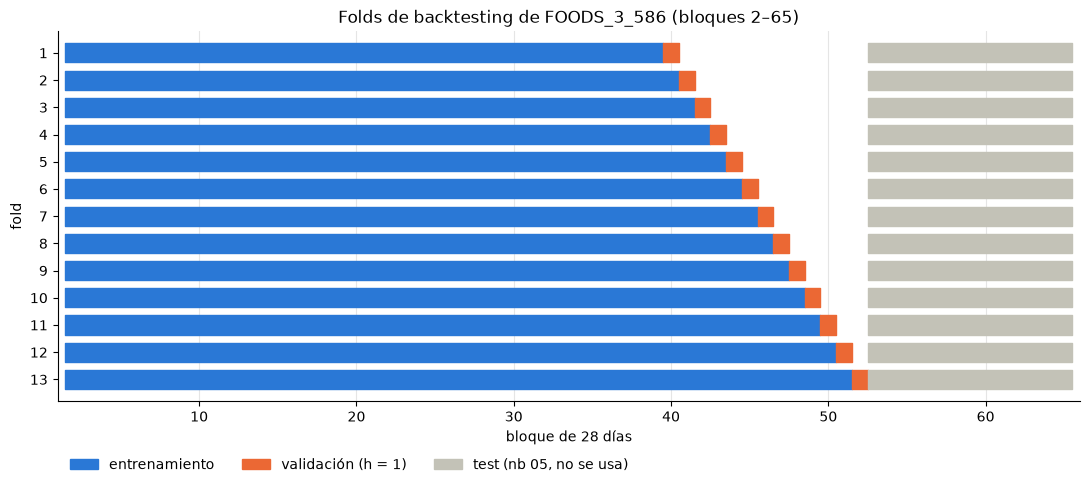

In [173]:
import matplotlib.pyplot as plt

TRAIN_COLOR, VALID_COLOR, TEST_COLOR = "#2a78d6", "#eb6834", "#c3c2b7"
ex = "FOODS_3_586"
d = boosting_data[boosting_data["item_id"] == ex]
first, last = d["block"].min(), d["block"].max()

fig, ax = plt.subplots(figsize=(11, 5))
for k in range(1, N_FOLDS + 1):
    train, valid = fold_masks(d, k)
    tr, va = d.loc[train, "block"], d.loc[valid, "block"]
    ax.broken_barh([(tr.min() - 0.5, tr.max() - tr.min() + 1)], (k - 0.35, 0.7), color=TRAIN_COLOR)
    ax.broken_barh([(va.min() - 0.5, 1)], (k - 0.35, 0.7), color=VALID_COLOR)
    test_blocks = d.loc[d["split"] == "test", "block"]
    ax.broken_barh([(test_blocks.min() - 0.5, len(test_blocks))], (k - 0.35, 0.7), color=TEST_COLOR)
ax.set(title=f"Folds de backtesting de {ex} (bloques {first}–{last})", xlabel="bloque de 28 días", ylabel="fold",
       yticks=range(1, N_FOLDS + 1), xlim=(first - 1, last + 1), ylim=(N_FOLDS + 0.8, 0.2))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (TRAIN_COLOR, VALID_COLOR, TEST_COLOR)]
ax.legend(handles, ["entrenamiento", "validación (h = 1)", "test (nb 05, no se usa)"], loc="upper left", frameon=False, ncol=3, bbox_to_anchor=(0, -0.12))
plt.tight_layout()
plt.show()

## Etapa 11 · Línea base: seasonal naive

**Objetivo:** pronosticar la ventana de backtesting con la línea base, medir su error en cada fold y calcular la escala del RMSSE de cada artículo.
**Entradas:** `features` (serie completa de unidades por artículo, incluido su primer bloque), `boosting_data` con `fold` (Etapa 10) y `snaive_m = 13` (`params.toml`, con historial).
**Salidas:** `snaive_valid` (pronóstico y error por artículo y fold), `rmsse_scale` (escala por artículo) y `snaive_item` (RMSSE de la línea base por artículo en los 13 folds).
**Decisión (usuario):**
- **En unidades:** ŷ_t = unidades del mismo artículo 13 bloques antes (el mismo periodo del año anterior). Calculamos el ratio, pero el pronóstico y el error se llevan a unidades, así que la línea base también se expresa en unidades. No se reentrena: en cada fold solo mira el bloque de hace 13.
- **Escala del RMSSE:** media de (y_t − y_{t−13})² con todo el train de cada artículo (todo lo anterior al test), como en M5. No cambia qué modelo gana dentro de un artículo (todos se dividen por la misma escala); solo pesa en el agregado. Con la ventana incluida, todos los artículos tienen al menos 26 bloques de train, así que al menos 13 pares para la escala.
- **Error por fold:** MAE, RMSE y WAPE sobre los 579 artículos (diagnóstico). **Por artículo:** RMSSE con sus 13 bloques de la ventana; es la referencia que cada candidato tendrá que mejorar en la Etapa 14.

In [174]:
from src.metrics import rmse, rmsse, seasonal_naive_scale, wape
from src.modeling import seasonal_naive

SNAIVE_M = cfg["forecast"]["snaive_m"]
assert SNAIVE_M == 13

In [175]:
features["snaive"] = seasonal_naive(features, SNAIVE_M)

In [176]:
# Pronóstico y error de la línea base en los bloques de la ventana (folds 1–13).
cell_of = targets.set_index("item_id")["cell"]
window = boosting_data.loc[boosting_data["fold"].between(1, N_FOLDS), ["item_id", "block", "fold", "units"]].astype({"item_id": str})
snaive_valid = window.merge(features[["item_id", "block", "snaive"]], on=["item_id", "block"], how="left", validate="one_to_one")
snaive_valid["error"] = snaive_valid["snaive"] - snaive_valid["units"]
snaive_valid["cell"] = snaive_valid["item_id"].map(cell_of)
assert len(snaive_valid) == 579 * N_FOLDS and snaive_valid["snaive"].notna().all()

# Comprobación manual: el pronóstico es la unidad del bloque t − 13 del mismo artículo.
u = features.set_index(["item_id", "block"])["units"]
expected = u.reindex(pd.MultiIndex.from_arrays([snaive_valid["item_id"], snaive_valid["block"] - SNAIVE_M])).to_numpy()
assert np.allclose(snaive_valid["snaive"], expected)

# Escala por artículo con todo su train.
train_units = features[features["split"] == "train"].sort_values(["item_id", "block"]).groupby("item_id")["units"]
rmsse_scale = train_units.apply(lambda s: seasonal_naive_scale(s.to_numpy(), SNAIVE_M))
n_pairs = train_units.size() - SNAIVE_M
assert rmsse_scale.notna().all() and (rmsse_scale > 0).all() and n_pairs.min() >= 13
print(f"escala: {len(rmsse_scale)} artículos, pares por artículo {n_pairs.min()}–{n_pairs.max()}")

per_fold = snaive_valid.groupby("fold").apply(lambda d: pd.Series({
    "MAE (unidades)": d["error"].abs().mean(), "RMSE (unidades)": rmse(d["units"], d["snaive"]), "WAPE": wape(d["units"], d["snaive"]),
}), include_groups=False)
display(per_fold.style.format({"MAE (unidades)": "{:,.1f}", "RMSE (unidades)": "{:,.1f}", "WAPE": "{:.1%}"}))

escala: 579 artículos, pares por artículo 13–39


,MAE (unidades),RMSE (unidades),WAPE
fold,,,
1,270.6,679.9,26.1%
2,286.0,614.5,27.4%
3,272.7,583.5,26.6%
4,314.9,"1,410.9",31.4%
5,282.9,743.4,29.7%
6,264.7,629.1,28.2%
7,250.1,655.6,28.1%
8,272.6,678.9,30.3%
9,247.0,621.6,27.3%


In [177]:
snaive_item = snaive_valid.groupby("item_id").apply(lambda d: pd.Series({
    "rmsse": rmsse(d["units"], d["snaive"], rmsse_scale[d.name]), "wape": wape(d["units"], d["snaive"]),
}), include_groups=False)
snaive_item["cell"] = snaive_item.index.map(cell_of)
assert snaive_item["rmsse"].notna().all() and len(snaive_item) == 579
display(snaive_item.groupby("cell")["rmsse"].describe(percentiles=[0.25, 0.5, 0.75]).round(3))
# Ejemplo con error absoluto y porcentual por bloque (diagnóstico: la constitución no usa MAPE como métrica).
ex = snaive_valid[snaive_valid["item_id"] == "FOODS_3_586"][["fold", "block", "units", "snaive", "error"]].copy()
ex["abs_error"] = ex["error"].abs()
ex["pct_error"] = ex["abs_error"] / ex["units"] * 100
display(ex.set_index("fold").style.format({"units": "{:,.0f}", "snaive": "{:,.0f}", "error": "{:+,.0f}", "abs_error": "{:,.0f}", "pct_error": "{:.1f} %"}))
print(f"FOODS_3_586 · error absoluto medio: {ex['abs_error'].mean():,.0f} unidades · error porcentual medio: {ex['pct_error'].mean():.1f} %"
      f" · WAPE (Σ|e| / Σy): {wape(ex['units'], ex['snaive']):.1%} · RMSSE: {snaive_item.loc['FOODS_3_586', 'rmsse']:.2f}")

,count,mean,std,min,25%,50%,75%,max
cell,,,,,,,,
AX,203.0,0.886,0.262,0.352,0.671,0.912,1.082,1.505
AY,248.0,0.868,0.286,0.292,0.617,0.878,1.085,1.510
AZ,128.0,0.903,0.354,0.125,0.632,0.903,1.173,1.600


,block,units,snaive,error,abs_error,pct_error
fold,,,,,,
1,40,"12,393","13,696","+1,303","1,303",10.5 %
2,41,"14,681","14,188",-493,493,3.4 %
3,42,"16,522","15,093","-1,429","1,429",8.6 %
4,43,"14,880","14,532",-348,348,2.3 %
5,44,"13,066","12,240",-826,826,6.3 %
6,45,"12,371","12,065",-306,306,2.5 %
7,46,"12,619","12,945",+326,326,2.6 %
8,47,"12,879","12,380",-499,499,3.9 %
9,48,"9,942","9,873",-69,69,0.7 %


FOODS_3_586 · error absoluto medio: 523 unidades · error porcentual medio: 4.0 % · WAPE (Σ|e| / Σy): 4.1% · RMSSE: 0.50


### 11.1 · Series por segmento: real vs seasonal naive

**Qué muestra:** para cada artículo, arriba el ratio y abajo las unidades, real contra seasonal naive, cada uno en su escala:
- **Ratio (tratado, 6a):** el seasonal naive toma el ratio de hace 13 bloques: el mismo cambio que hubo hace un año. Los ratios > 2 están vacíos (hueco en la línea) y una línea punteada vertical marca el bloque.
- **Unidades:** el seasonal naive toma las unidades de hace 13 bloques (la línea base de esta etapa, con la que se mide el error). Las unidades son las reales: el tratamiento del ratio no las cambia.

**Leyenda:** una sola, arriba (real, seasonal naive y bloque tratado). **Error:** el del seasonal naive en la ventana de backtesting, siempre en porcentaje (WAPE = Σ|error| ÷ Σ real), en el título de cada panel. El seasonal naive empieza un año después del inicio de cada artículo.
**Decisión:** 5 artículos al azar de cada segmento (AX, AY y AZ), elegidos con la semilla de `params.toml` (`features.seed`) para que sean siempre los mismos. Solo se grafica el train (hasta el último bloque de la ventana de backtesting, sombreada): el test no se mira hasta el nb 05.

In [178]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

REAL_COLOR, SNAIVE_COLOR, WINDOW_COLOR, TREATED_COLOR = "#2a78d6", "#eb6834", "#f1f0ec", "#6b6b6b"

def plot_item(item):
    # Ratio (arriba) y unidades (abajo) del train de un artículo: real vs seasonal naive.
    d = features[(features["item_id"] == item) & (features["split"] == "train")].sort_values("block")
    snaive_ratio = d["ratio"].shift(SNAIVE_M)   # seasonal naive sobre el ratio: el ratio de hace 13 bloques
    in_win = d["backtest"]
    win = d.loc[in_win, "block"]
    ok = in_win & d["ratio"].notna() & snaive_ratio.notna()
    wape_ratio = wape(d.loc[ok, "ratio"], snaive_ratio[ok])
    wape_units = wape(d.loc[in_win, "units"], d.loc[in_win, "snaive"])
    fig, (ax_r, ax_u) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
    for ax in (ax_r, ax_u):
        ax.axvspan(win.min() - 0.5, win.max() + 0.5, color=WINDOW_COLOR, zorder=0)
        for b in d.loc[d["ratio_treated"], "block"]:
            ax.axvline(b, color=TREATED_COLOR, linewidth=0.8, linestyle=":", zorder=1)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
        ax.set_axisbelow(True)
    ax_r.plot(d["block"], d["ratio"], color=REAL_COLOR, linewidth=2)
    ax_r.plot(d["block"], snaive_ratio, color=SNAIVE_COLOR, linewidth=2)
    ax_r.axhline(1, color="#9a9a9a", linewidth=0.8, linestyle="--")
    ax_r.set(ylabel="ratio")
    ax_r.set_title(f"Ratio · WAPE del seasonal naive en la ventana: {wape_ratio:.1%}", loc="left", fontsize=10)
    ax_u.plot(d["block"], d["units"], color=REAL_COLOR, linewidth=2)
    ax_u.plot(d["block"], d["snaive"], color=SNAIVE_COLOR, linewidth=2)
    ax_u.set(ylabel="unidades", xlabel="bloque de 28 días")
    ax_u.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax_u.set_title(f"Unidades · WAPE del seasonal naive en la ventana: {wape_units:.1%}", loc="left", fontsize=10)
    ax_r.text(win.mean(), 0.98, "ventana de backtesting", transform=ax_r.get_xaxis_transform(), ha="center", va="top", fontsize=9, color="#6b6b6b")
    handles = [Line2D([], [], color=REAL_COLOR, linewidth=2, label="real"),
               Line2D([], [], color=SNAIVE_COLOR, linewidth=2, label="seasonal naive"),
               Line2D([], [], color=TREATED_COLOR, linewidth=0.8, linestyle=":", label="ratio tratado (> 2)")]
    fig.suptitle(f"{item} ({cell_of[item]})", x=0.01, ha="left", fontsize=12)
    fig.legend(handles=handles, loc="upper right", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.99, 1.0))
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

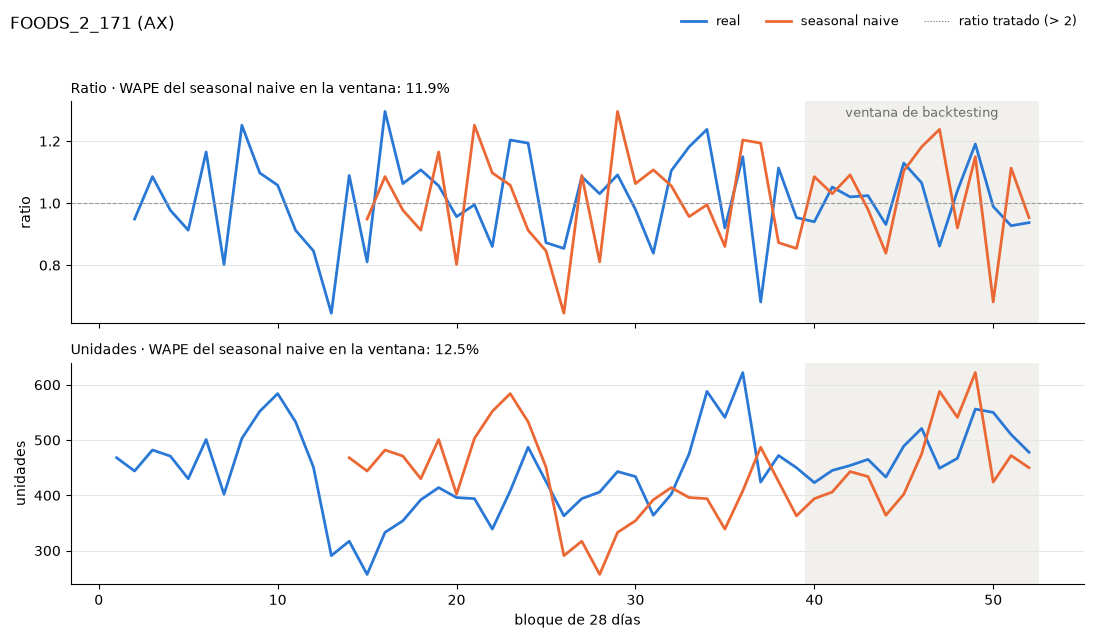

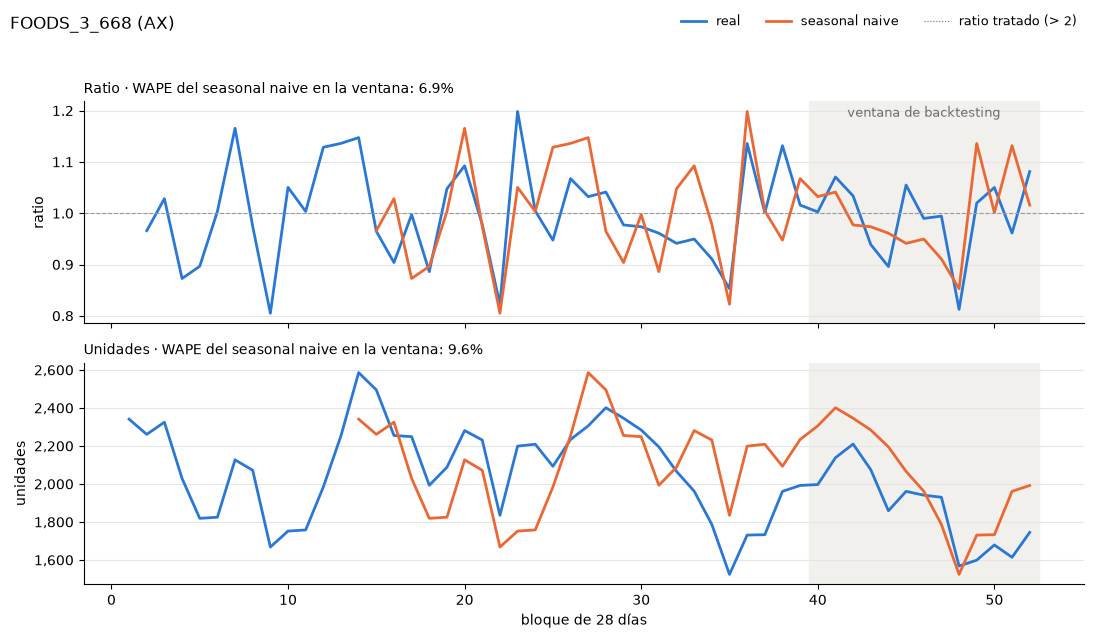

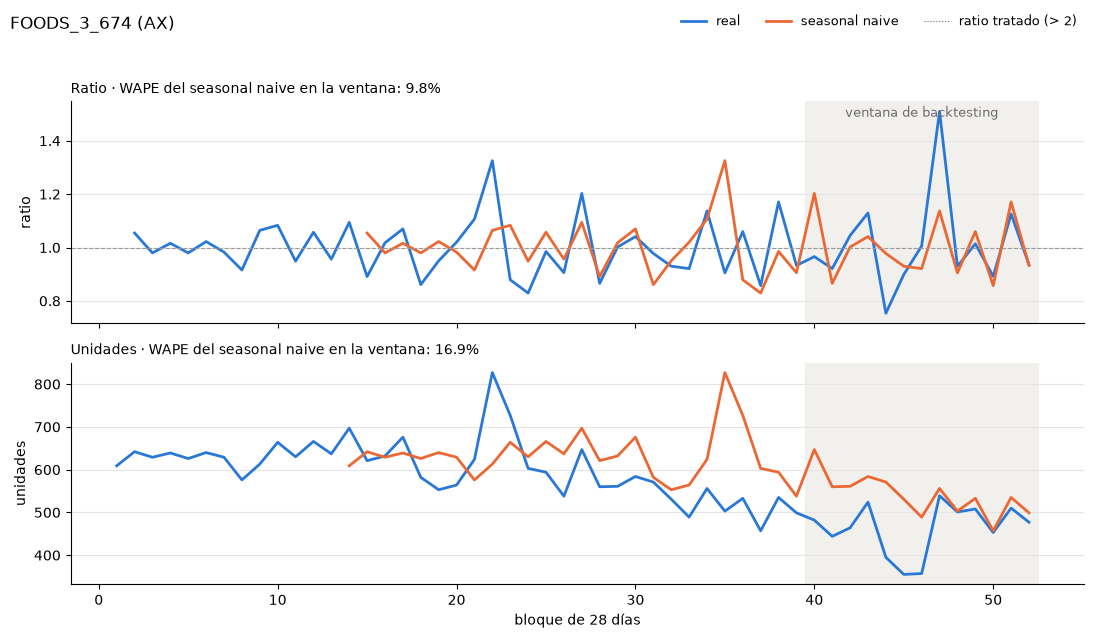

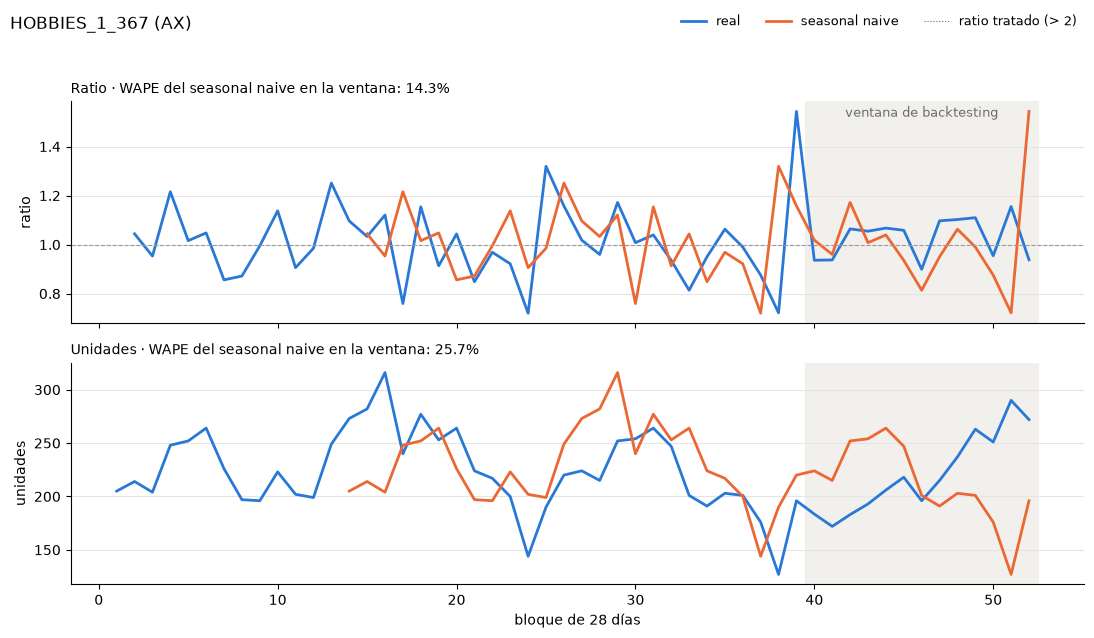

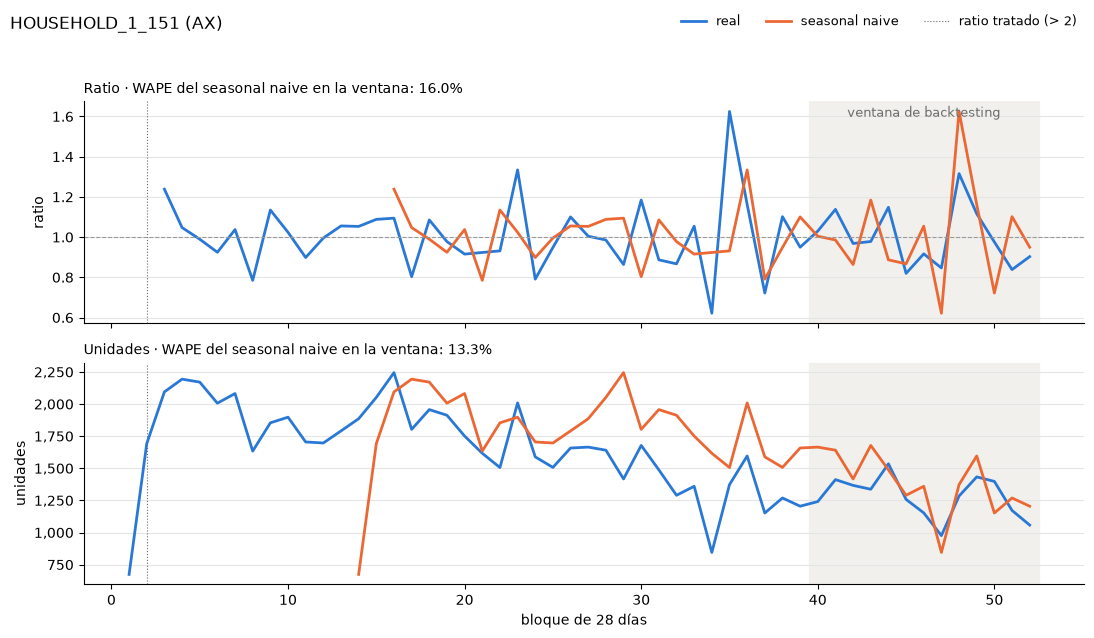

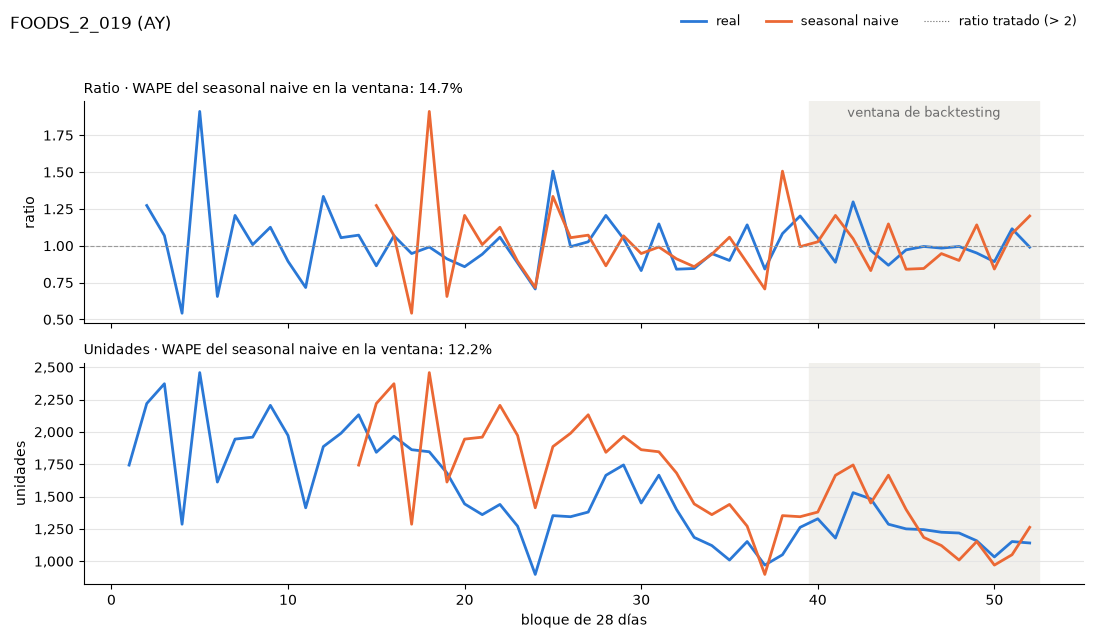

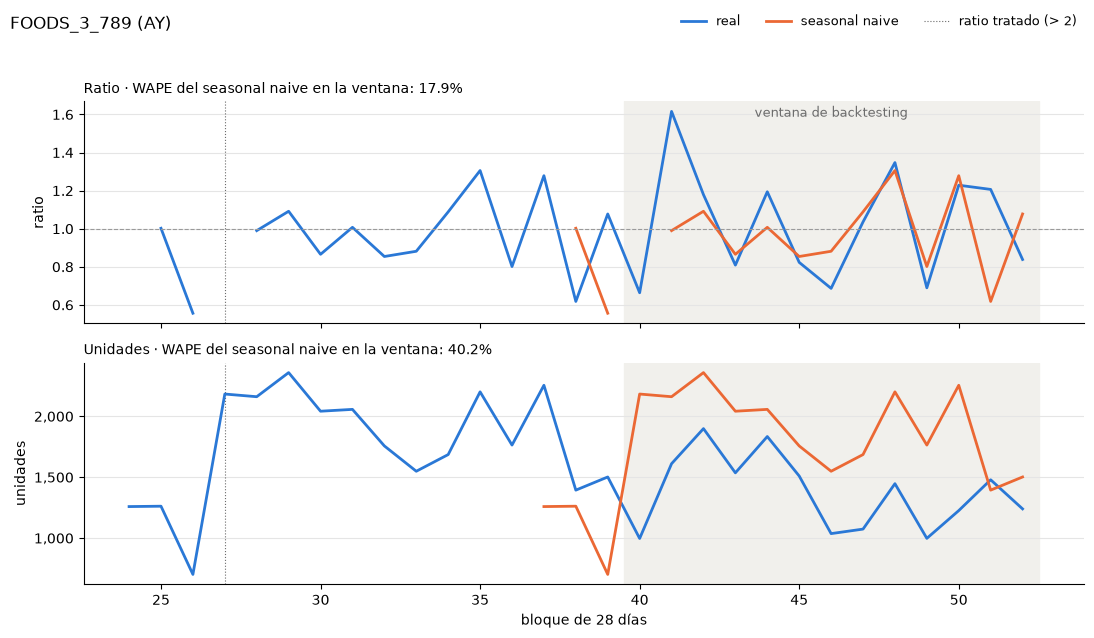

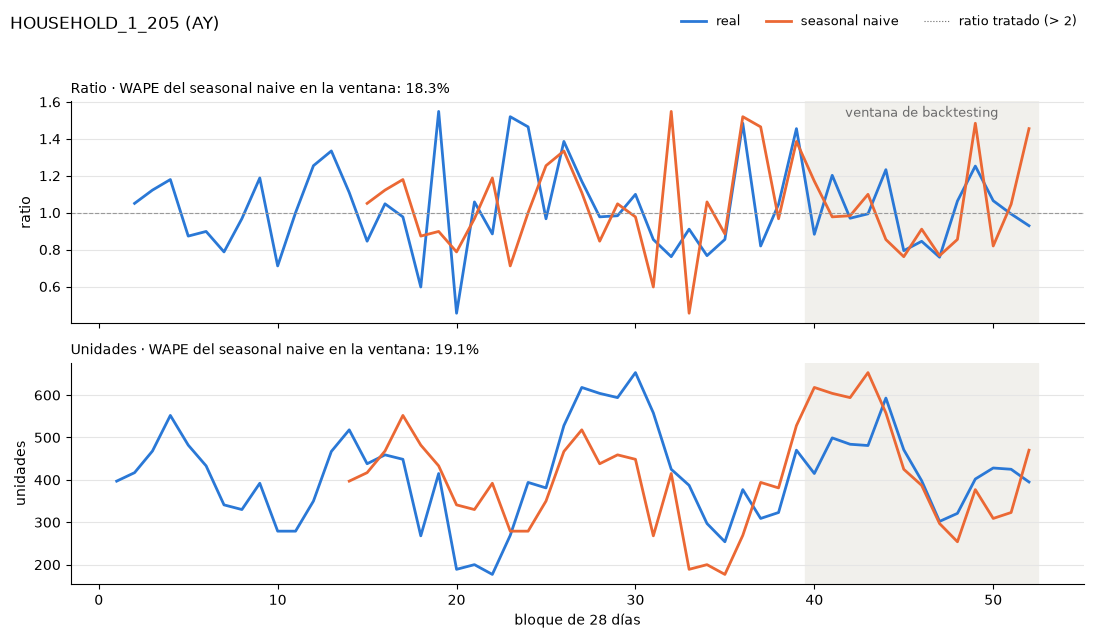

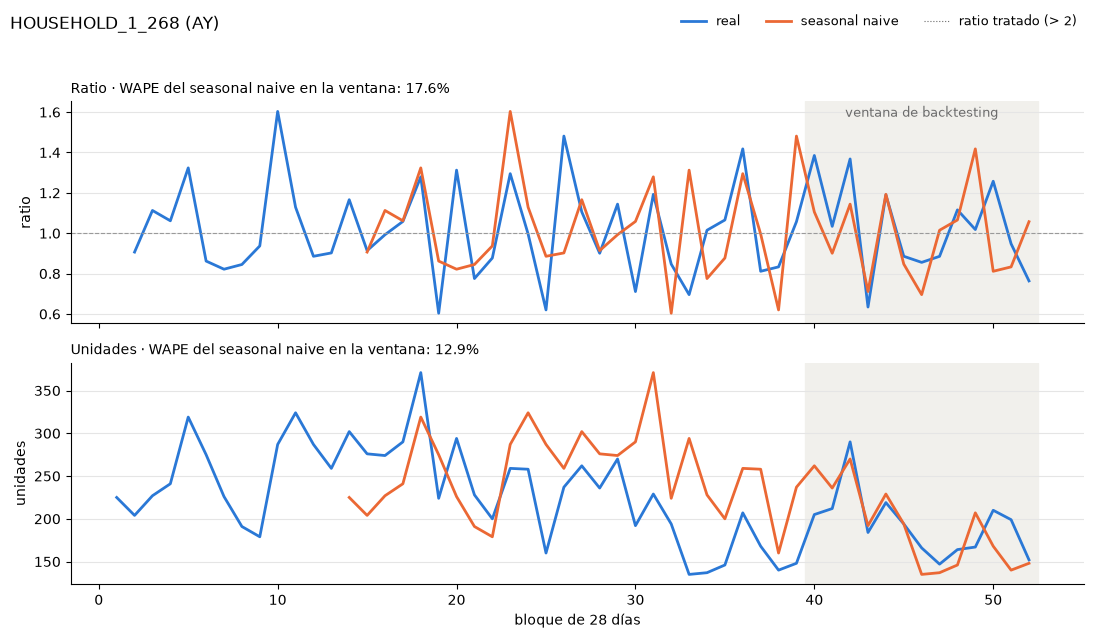

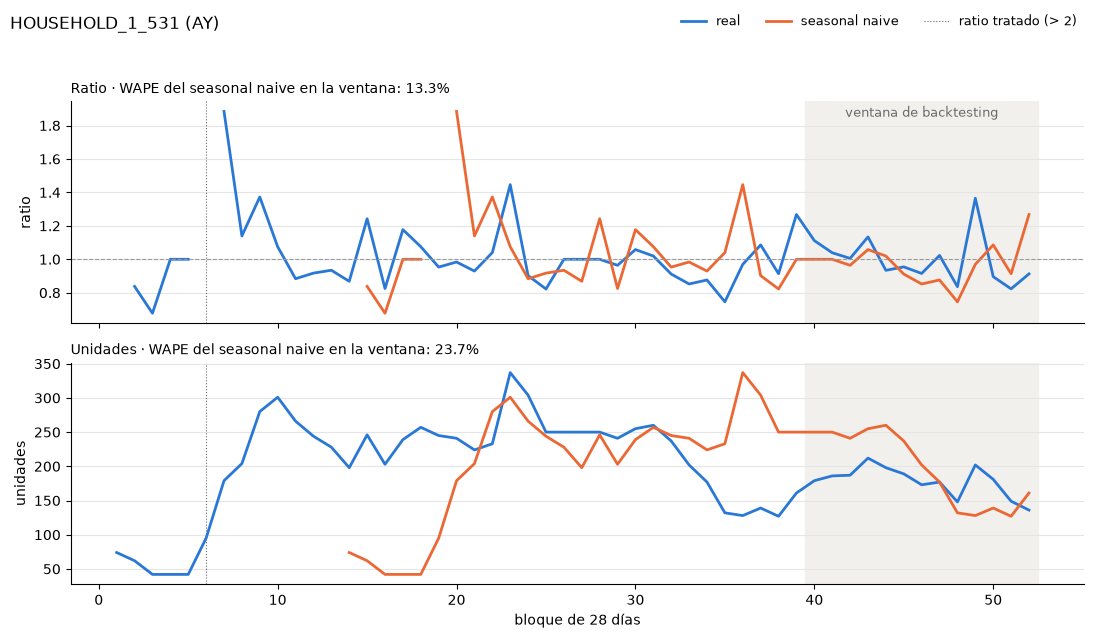

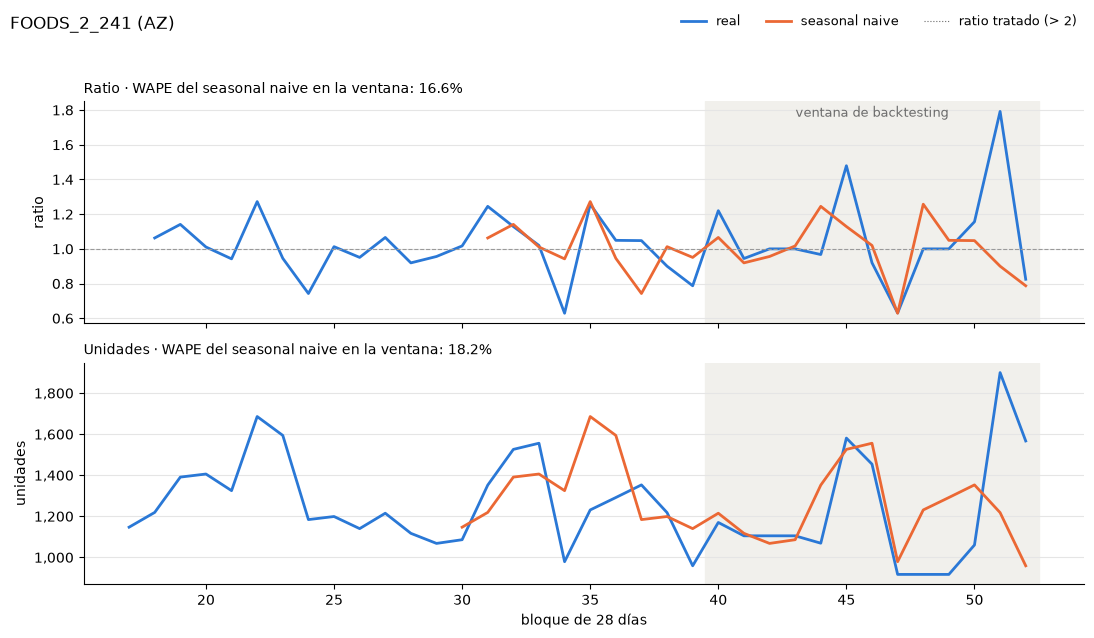

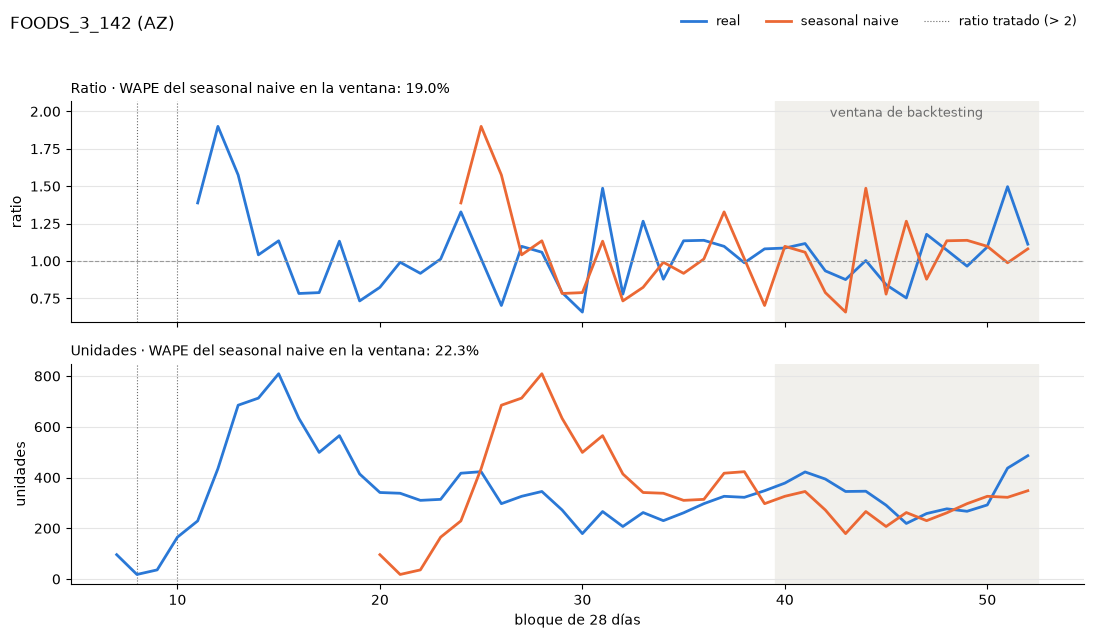

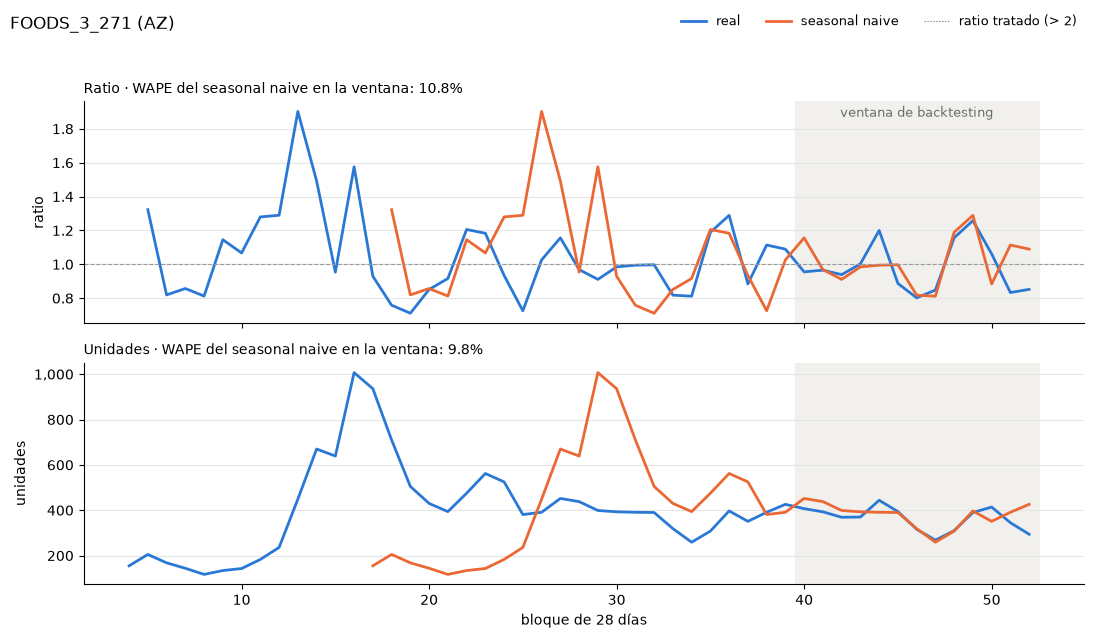

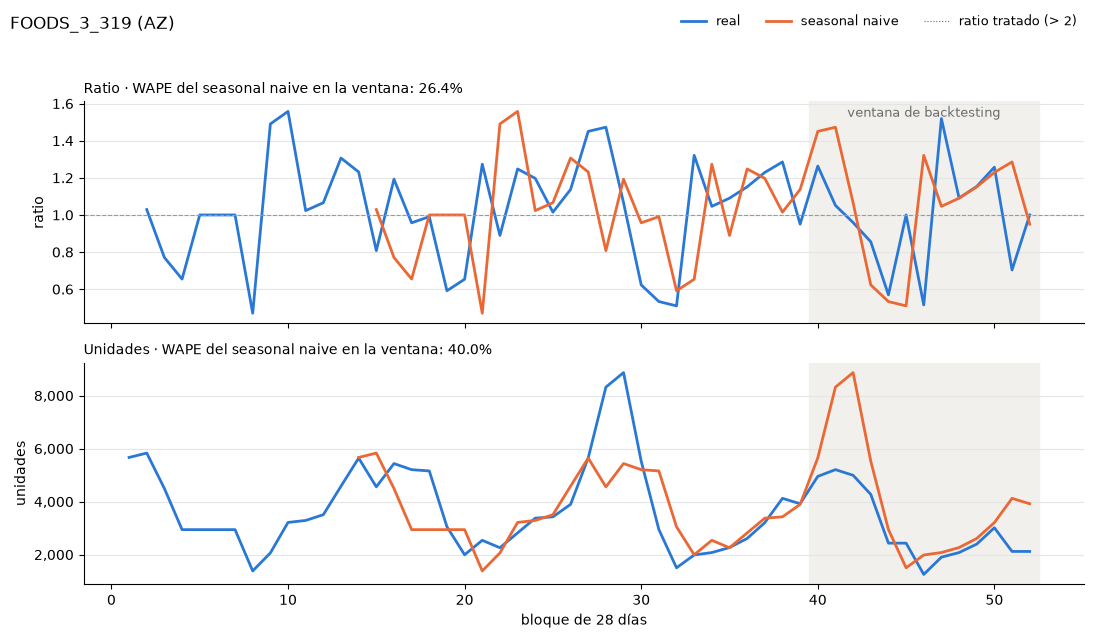

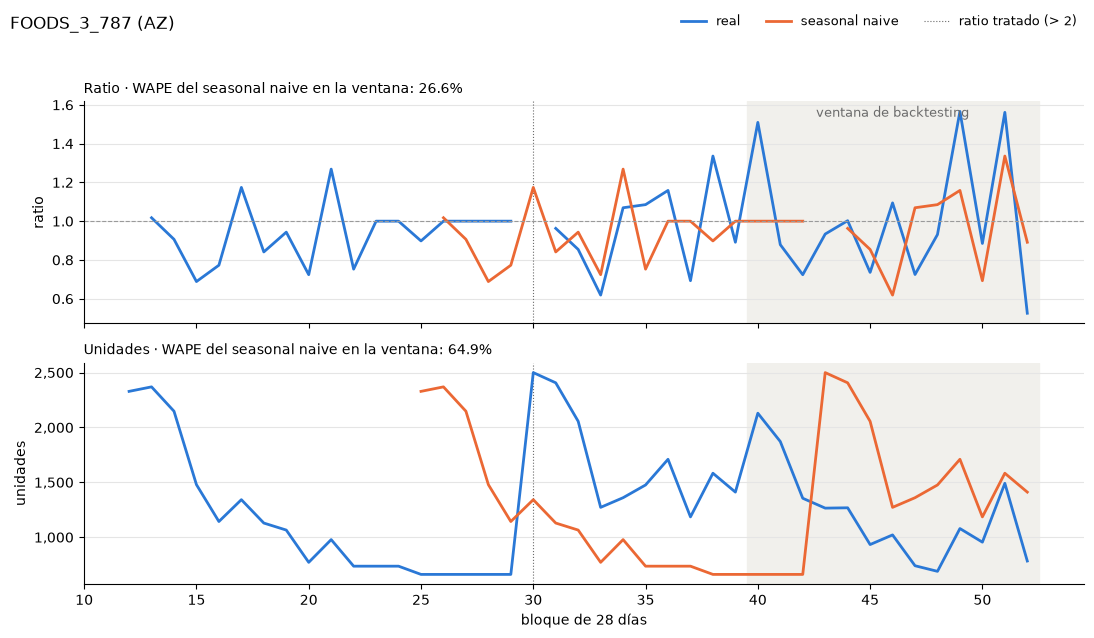

In [179]:
rng = np.random.default_rng(SEED)
modeled = np.sort(features["item_id"].unique())
for cell in ["AX", "AY", "AZ"]:
    pool = [i for i in modeled if cell_of[i] == cell]
    for item in sorted(rng.choice(pool, size=5, replace=False)):
        plot_item(item)

### 11.2 · Series con ratios tratados

**Qué muestra:** el mismo gráfico para 10 artículos elegidos al azar (con la semilla) entre los que tienen algún ratio tratado en el train (6a: ratio > 2, vacío).
**Para qué:** comprobar que los picos del ratio ya no aparecen y ver qué había en esos bloques: casi siempre un bloque anterior con días enmascarados o completado (la tabla de causas de la 6a).

ratios tratados en el train: 203 en 140 artículos


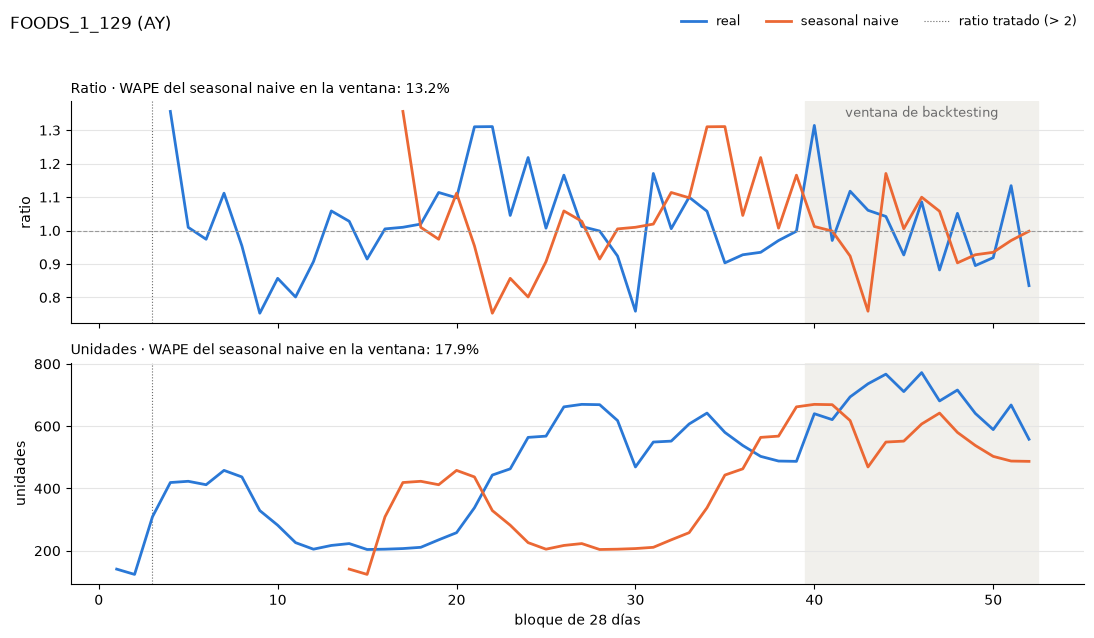

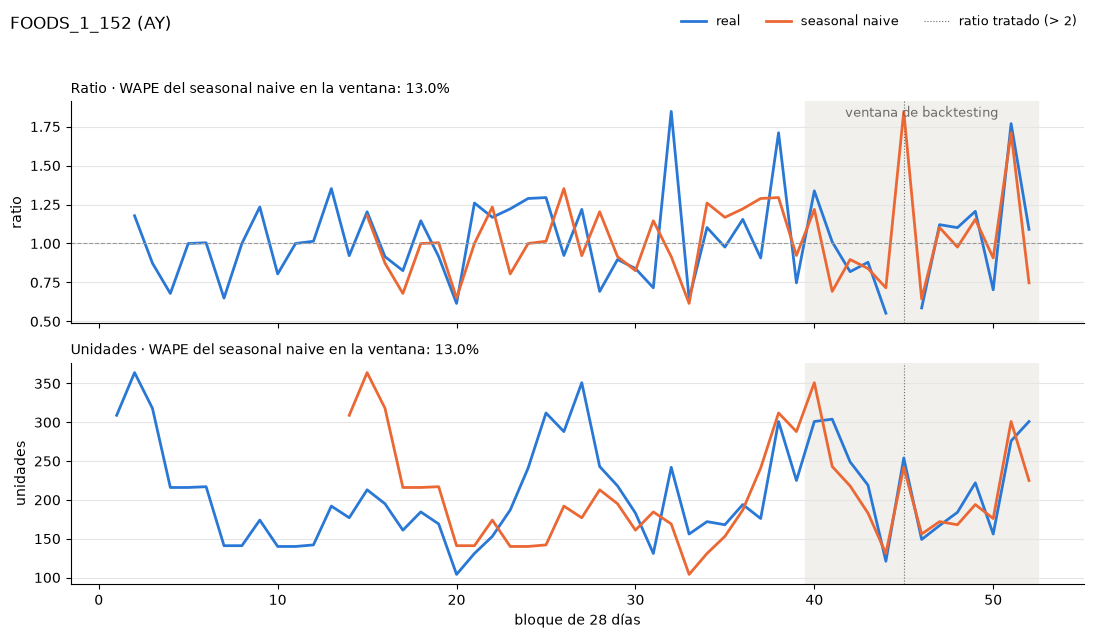

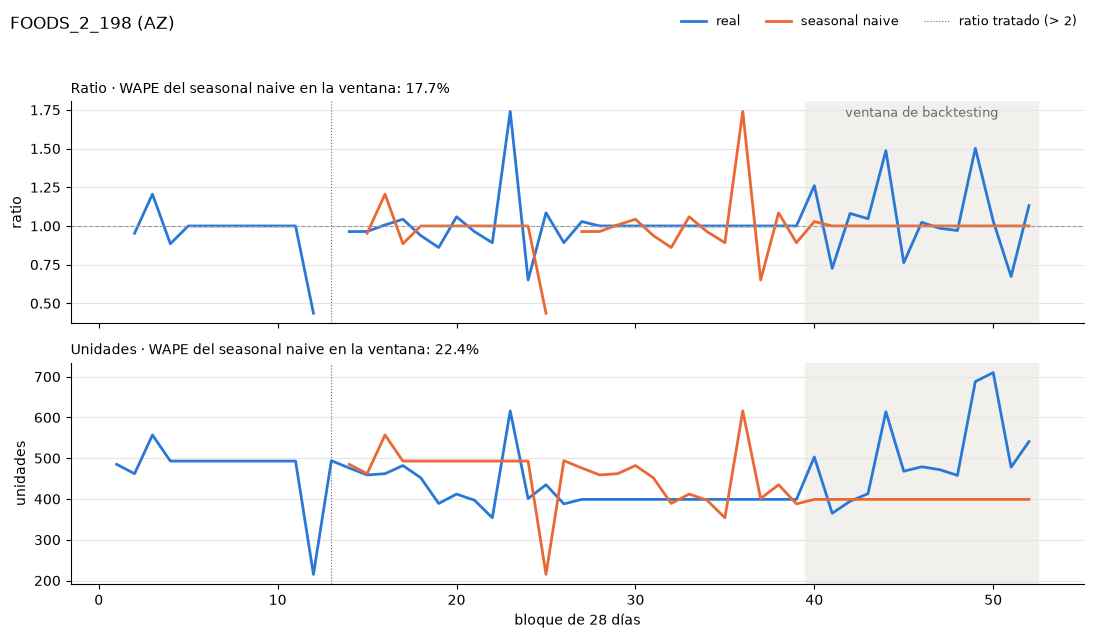

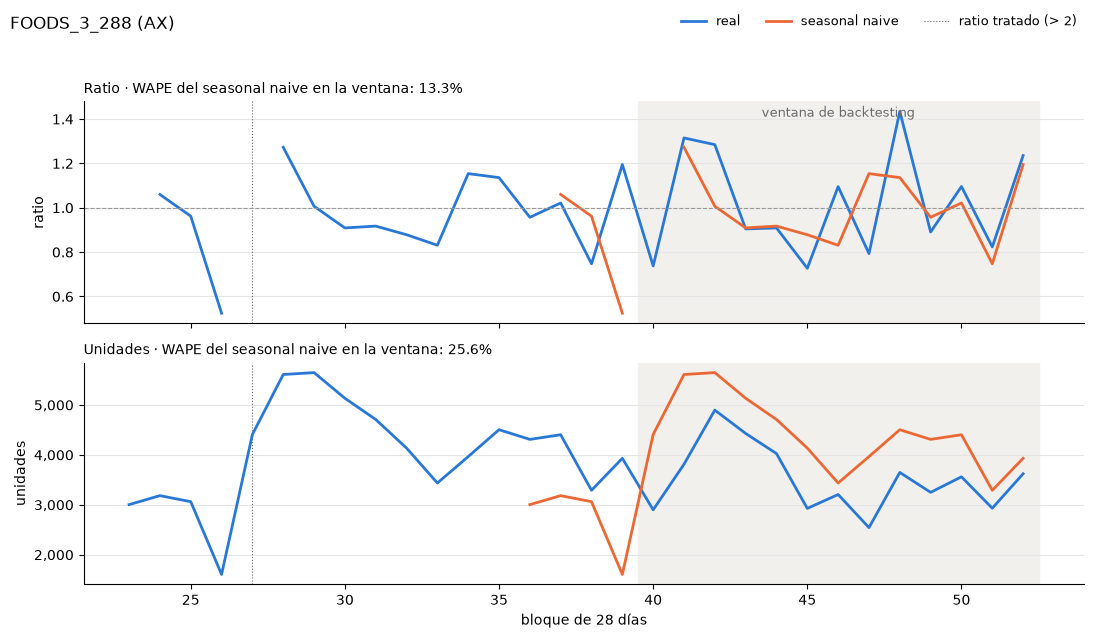

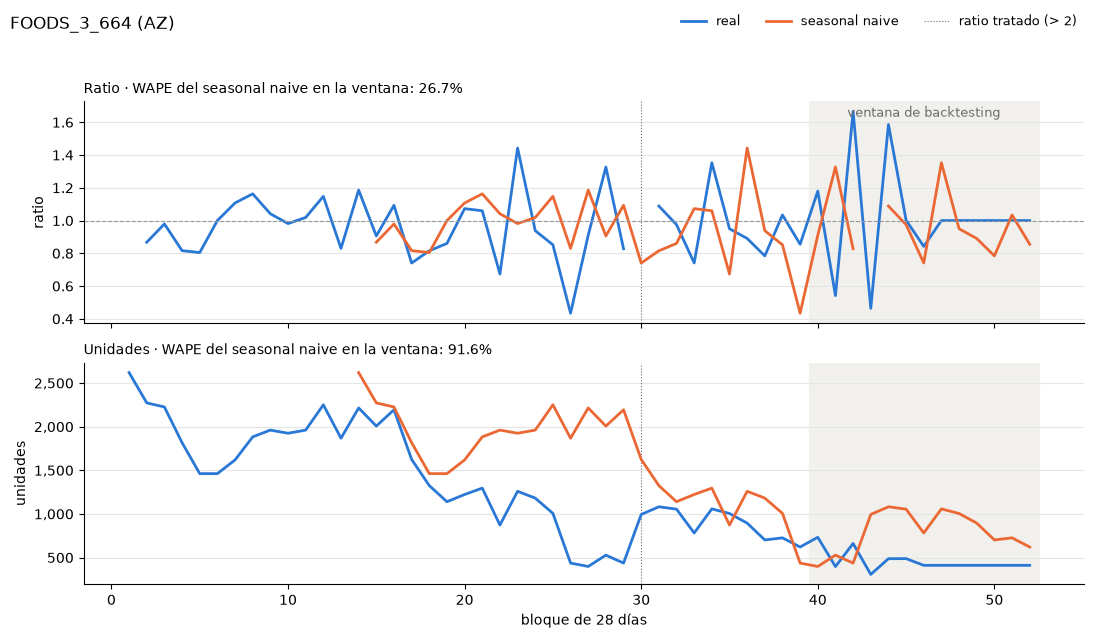

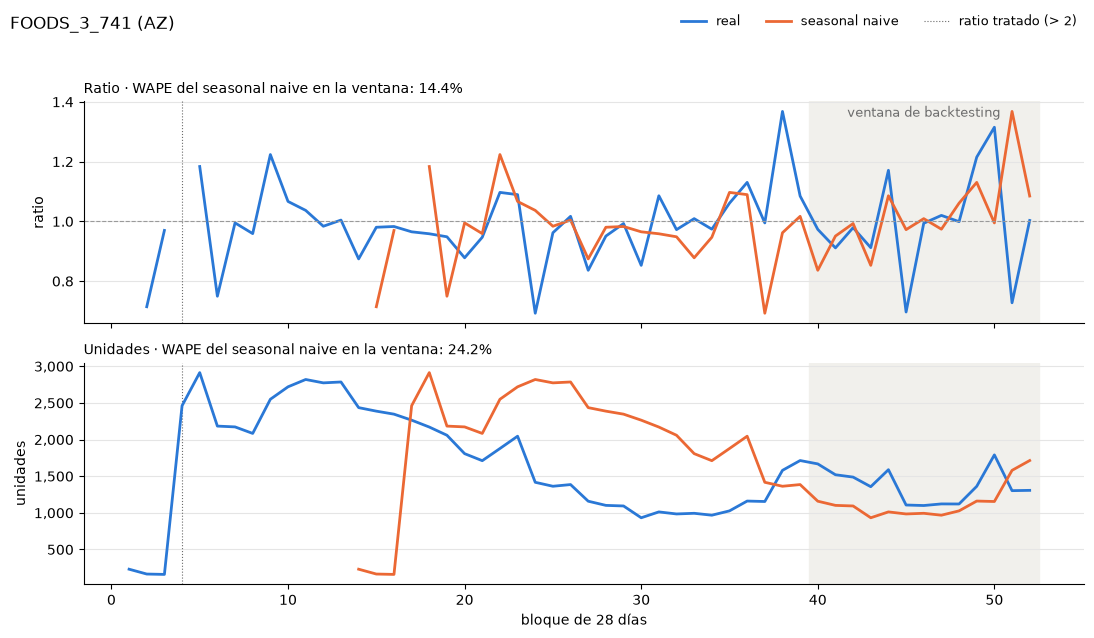

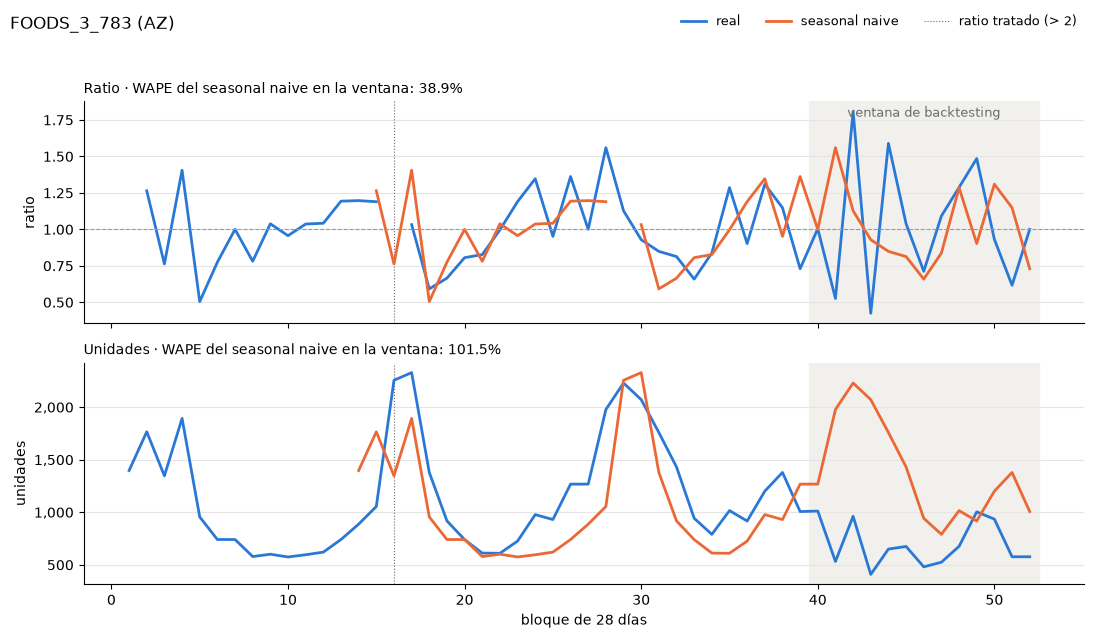

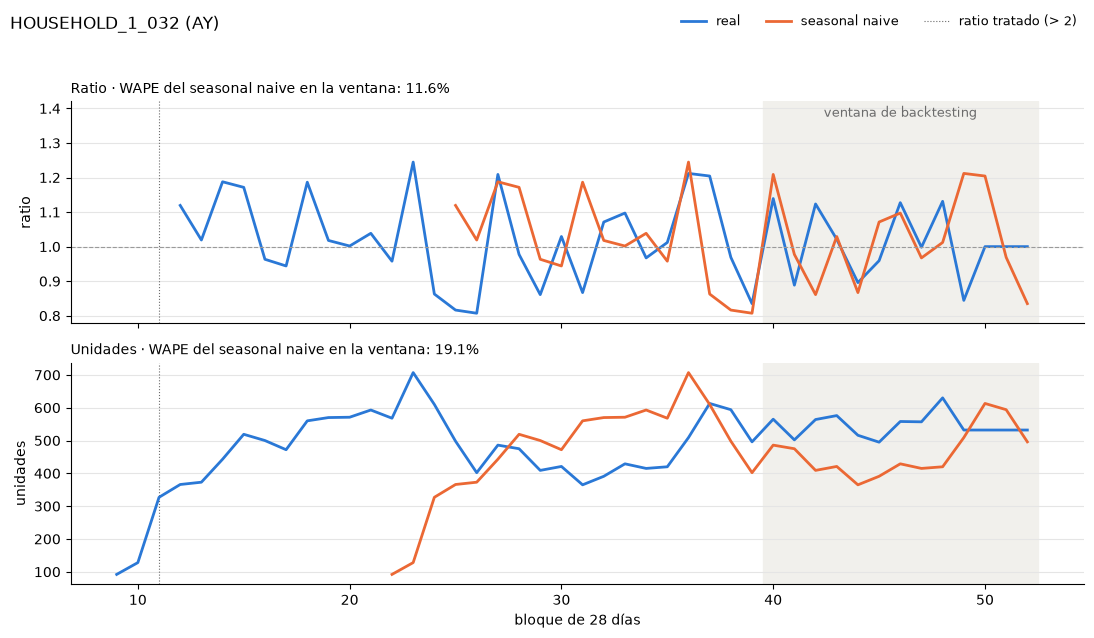

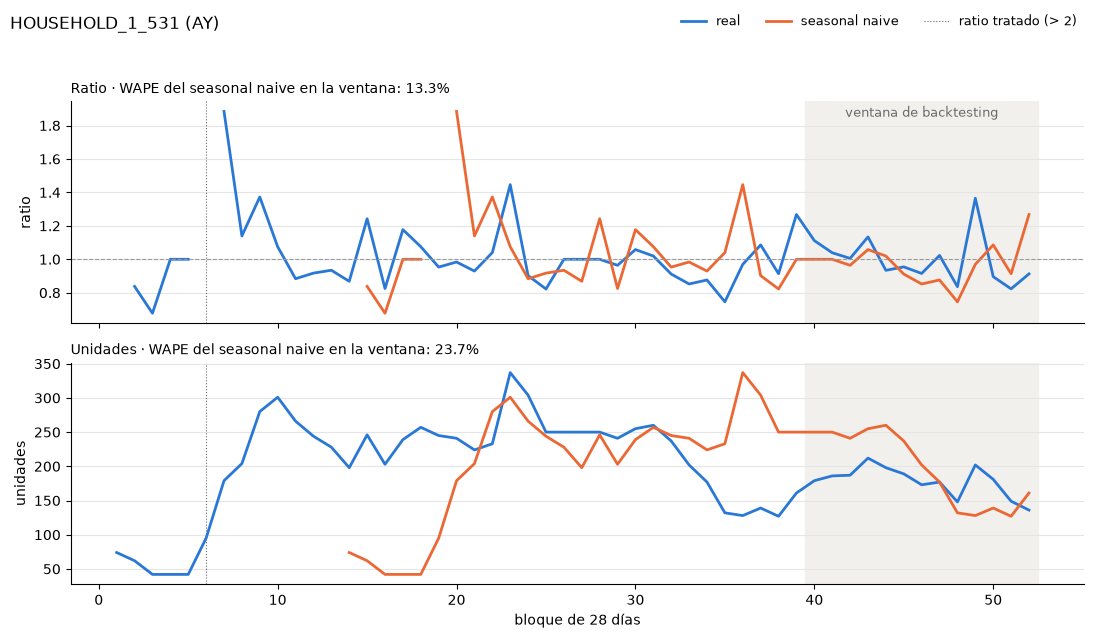

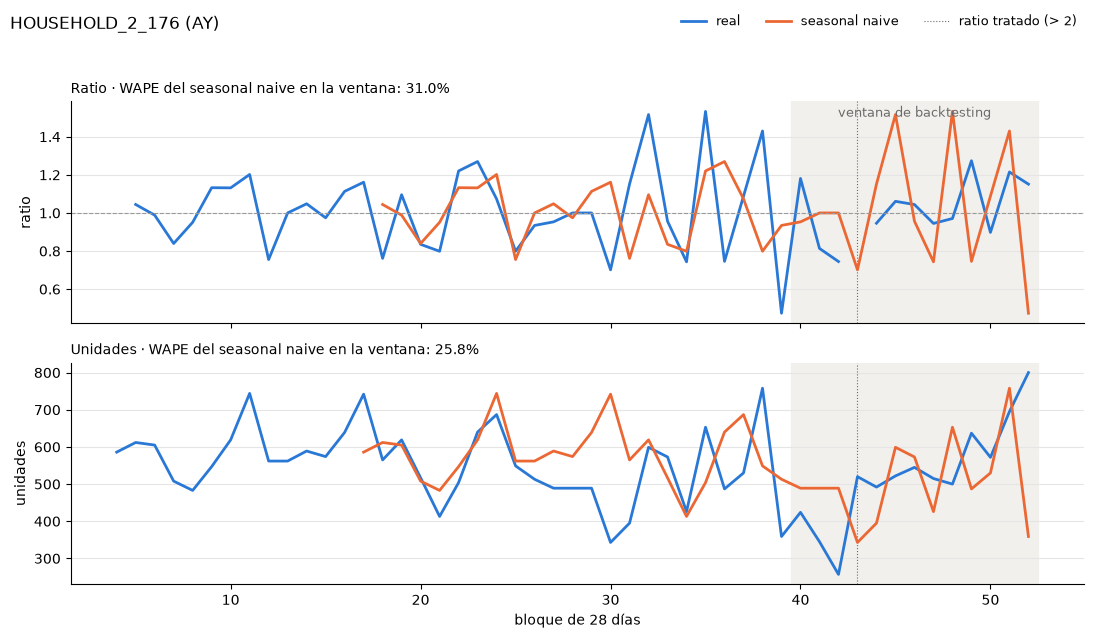

In [180]:
train_rows = features[features["split"] == "train"]
treated_items = np.sort(train_rows.loc[train_rows["ratio_treated"], "item_id"].unique())
print(f"ratios tratados en el train: {int(train_rows['ratio_treated'].sum())} en {len(treated_items)} artículos")
rng = np.random.default_rng(SEED)
for item in sorted(rng.choice(treated_items, size=min(10, len(treated_items)), replace=False)):
    plot_item(item)